# Auditoría térmica de la forma de la curva de CO₂

Este notebook prueba si la temperatura debe actuar como un **reloj de fermentación** que comprime o ensancha la trayectoria completa. Mantiene `theta_full`, la formulación nutricional y los parámetros del pool seleccionados en `lab019_021_co2_production_blocks_audit` congelados mientras compara:

1. referencia actual;
2. reloj térmico residual;
3. adaptación inicial dependiente de temperatura;
4. reloj + adaptación;
5. reloj + adaptación + liberación térmica $k_{release}(T)$.

La nutrición conserva exactamente la propuesta anterior: rampa histórica de actividad y respuesta cinética, seguida del kernel transitorio normalizado de subida y decaimiento. LAB005/007/008 y LAB019/020/021 participan en el ajuste de los parámetros térmicos; LAB011/012 seleccionan la estructura; LAB016/017/018 permanecen como holdout externo. No se escriben figuras ni tablas en `results`.


In [1]:
from __future__ import annotations

import csv
import io
import json
import math
import re
import sys
from dataclasses import replace
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
from IPython import get_ipython
_ip = get_ipython()
if _ip is not None:
    _ip.run_line_magic("matplotlib", "inline")
import numpy as np
import openpyxl
import pandas as pd
from IPython.display import Markdown, SVG, display

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "fermentation_model").exists())
FM = ROOT / "fermentation_model"
LAB2026 = FM / "laboratory_2026"
DATA_DIR = FM / "data" / "mem2026" / "LAB019-021"
DATA_016_018_DIR = FM / "data" / "mem2026" / "LAB016-018"
REFERENCE_RESULTS_DIR = LAB2026 / "results" / "lab019_021_theta_full_holdout"

for path in (FM, LAB2026, FM / "pilot_2025"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from shared import run_new_must_glycerol_estimability_doe as base
from shared import run_secondary_joint_campaign_doe as joint
from shared import run_secondary_v2_model_evaluation as secondary_v2
from laboratory_2026 import run_estimability_historical_by_medium as natural_loader
from laboratory_2026 import run_co2_matrix_cross_validation_2026 as co2_cross

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5})


def display_inline_figure(fig, dpi=90):
    """Embebe SVG vectorial en el output sin escribir archivos."""
    buffer = io.StringIO()
    fig.savefig(buffer, format='svg', bbox_inches='tight', facecolor='white')
    plt.close(fig)
    display(SVG(data=buffer.getvalue()))
    buffer.close()

LABS = ("LAB019", "LAB020", "LAB021")
FERMENTER = {"LAB019": "F1", "LAB020": "F2", "LAB021": "F3"}
MATCHED_ORIGINAL = {"LAB019": "LAB004", "LAB020": "LAB006", "LAB021": "LAB009"}
COLORS = {"LAB019": "#4c72b0", "LAB020": "#55a868", "LAB021": "#c44e52"}
T0 = pd.Timestamp("2026-09-21 17:00:00")
# Hora y dosis reales del segundo pulso: hoja Nutricion, no un valor heredado del ajuste histórico.
nutrition_wb = openpyxl.load_workbook(
    DATA_DIR / "Mediciones-Offline-LAB019-021.xlsx", read_only=True, data_only=True
)
pulse2_rows = [
    row for row in nutrition_wb["Nutricion"].iter_rows(min_row=2, values_only=True)
    if row[0] in LABS and row[2] == "Pulso 2"
]
nutrition_wb.close()
assert len(pulse2_rows) == len(LABS)
assert {row[0] for row in pulse2_rows} == set(LABS)
PULSE2_DT = {row[0]: pd.Timestamp(row[3]) for row in pulse2_rows}
PULSE2_H = {lab: (stamp - T0).total_seconds() / 3600.0 for lab, stamp in PULSE2_DT.items()}
pulse2_doses = {row[0]: float(row[4]) / 1000.0 for row in pulse2_rows}  # mg/L -> kg/m³
assert len(set(pulse2_doses.values())) == 1, "el modelo usa una dosis común para los tres lotes"
DELTA_N_KG_M3 = next(iter(pulse2_doses.values()))
GRID_H = 0.25
CO2_FACTOR_G_L_H_PER_SCCM = 44.0095 * 60.0 * 0.74 / (1000.0 * 24.16 * 2.0)
assert np.isclose(CO2_FACTOR_G_L_H_PER_SCCM, 0.0404391928807947)
print("ROOT:", ROOT)
print("t0:", T0, "| pulse 2 [h]:", PULSE2_H)

pd.set_option("display.max_rows", 120)


ROOT: D:\claud\Desktop\Universidad\Memoria\Model\pyomo-doe
t0: 2026-09-21 17:00:00 | pulse 2 [h]: {'LAB019': 64.33333333333333, 'LAB020': 71.66666666666667, 'LAB021': 47.5}


In [2]:
THETA_FULL_PATH = LAB2026 / "results" / "estimability_historical_natural" / "theta_natural_full.csv"
THETA_AUX_PATH = LAB2026 / "results" / "final_operational_doe_v2" / "theta_final_operational_v2.csv"
CO2_PARAM_PATH = LAB2026 / "results" / "co2_matrix_cross_validation_2026_full_theta_sccm_corrected_no_lab010" / "three_state_co2_parameters.csv"

theta_table = pd.read_csv(THETA_FULL_PATH)
theta_full = dict(zip(theta_table["parameter"], theta_table["theta"].astype(float)))
assert set(base.FULL17) == set(theta_full), (set(base.FULL17) - set(theta_full), set(theta_full) - set(base.FULL17))

theta_aux = pd.read_csv(THETA_AUX_PATH, index_col=0).iloc[:, 0].astype(float).to_dict()
theta_model = {**theta_aux, **theta_full}  # theta_full siempre prevalece en la capa cinética

co2_parameter_table = pd.read_csv(CO2_PARAM_PATH)
co2_parameter_table = co2_parameter_table[
    co2_parameter_table["state"].eq("C_full_theta_refit")
    & co2_parameter_table["calibration_matrix"].eq("natural")
].copy()
co2_params = dict(zip(co2_parameter_table["parameter"], co2_parameter_table["estimate"].astype(float)))
assert set(co2_cross.PARAMETER_BOUNDS).issubset(co2_params)



display(theta_table)
display(co2_parameter_table[["parameter", "estimate", "active_bound"]])


,parameter,theta,source
0,mu0,0.078728,laboratory_2026\results\estimability_historica...
1,sN,8.751446,shared\results\new_must_glycerol_overnight_val...
2,qN,0.021080,laboratory_2026\results\estimability_historica...
3,qXG,0.081491,shared\results\new_must_glycerol_overnight_val...
4,qXF,0.070933,shared\results\new_must_glycerol_overnight_val...
5,betaG0,0.428878,laboratory_2026\results\estimability_historica...
6,sG,0.097455,shared\results\new_must_glycerol_overnight_val...
7,betaF0,3.440399,laboratory_2026\results\estimability_historica...
8,sF,0.178295,shared\results\new_must_glycerol_overnight_val...
9,qEG,1.712807,laboratory_2026\results\estimability_historica...


,parameter,estimate,active_bound
45,kCO2_release_h,0.278349,False
46,CO2sat_scale,2.498908,True
47,O2_qmax_mg_gdw_h,0.253137,False
48,O2_initial_scale,0.179606,False
49,pulse_t_rise_h,56.741847,False
50,pulse_activity_gain,0.250011,True
51,chem_activation_start_fraction,0.741575,False
52,chem_activation_duration_fraction,0.457773,False
53,matrix_gain,1.602222,False


## Parámetros editables y protocolo

El reloj adicional usa

$$s_T(t)=\exp\left[B_{extra}\left(\frac{1}{T_{ref}}-\frac{1}{T(t)}\right)\right],\qquad
\tau(t)=\int_0^t s_T(\xi)\,d\xi.$$

`B_clock_extra_K=0` reproduce el reloj del modelo actual. La adaptación se representa como

$$a_{adapt}(t)=1-\exp[-\tau(t)/\tau_{adapt,ref}].$$

La transferencia térmica opcional usa

$$k(T)=k_{ref}\exp\left[B_{release}\left(\frac{1}{T_{ref}}-\frac{1}{T}\right)\right].$$

Los parámetros manuales del final no alteran los ajustes ni el ranking.


In [3]:
AUDIT_CONFIG = {
    'historical_weight': 1.0,
    'recent_weight': 2.0,
}

THERMAL_CONFIG = {
    'reference_temperature_C': 20.0,
    'max_nfev': 260,
    'bounds': {
        'B_clock_extra_K': (0.0, 12000.0),
        'tau_adapt_ref_h': (1.0, 60.0),
        'B_release_K': (0.0, 12000.0),
    },
    'multistart': (
        {'B_clock_extra_K': 0.0, 'tau_adapt_ref_h': 8.0, 'B_release_K': 0.0},
        {'B_clock_extra_K': 2500.0, 'tau_adapt_ref_h': 16.0, 'B_release_K': 1500.0},
        {'B_clock_extra_K': 6000.0, 'tau_adapt_ref_h': 24.0, 'B_release_K': 5000.0},
        {'B_clock_extra_K': 10000.0, 'tau_adapt_ref_h': 40.0, 'B_release_K': 9000.0},
    ),
}

# Ajuste seleccionado en el audit anterior: actual_sin_O2.
# theta_full, rampa y parámetros del pool permanecen congelados en esta prueba.
REFERENCE = {
    'pulse_t_rise_h': 56.741847,
    'pulse_activity_gain': 0.250011,
    'kCO2_release_h': 0.09453,
    'CO2sat_scale': 2.5,
    'matrix_gain': 1.44355,
    'A': 1.5,
    'tau_rise_h': 0.62702,
    'tau_decay_h': 4.31256,
}

MODEL_SPECS = {
    'actual': {'clock': False, 'adaptation': False, 'release_T': False, 'label': 'Actual congelado', 'color': '0.45'},
    'reloj': {'clock': True, 'adaptation': False, 'release_T': False, 'label': 'Reloj térmico', 'color': '#0072B2'},
    'adaptacion': {'clock': False, 'adaptation': True, 'release_T': False, 'label': 'Adaptación', 'color': '#D55E00'},
    'reloj_adaptacion': {'clock': True, 'adaptation': True, 'release_T': False, 'label': 'Reloj + adaptación', 'color': '#009E73'},
    'termico_completo': {'clock': True, 'adaptation': True, 'release_T': True, 'label': 'Reloj + adaptación + k(T)', 'color': '#CC79A7'},
}

# EDITAR AQUÍ después de ejecutar todo una vez. Luego ejecutar esta celda y el Explorador manual.
MANUAL = {
    'labs': ('LAB019', 'LAB020', 'LAB021'),
    'B_clock_extra_K': 4000.0,
    'tau_adapt_ref_h': 18.0,
    'B_release_K': 2500.0,
    'clock': True,
    'adaptation': True,
    'release_T': True,
}

assert all(value > 0 for value in AUDIT_CONFIG.values())
assert all(REFERENCE[name] > 0 for name in REFERENCE)


In [4]:
import hashlib

PROTECTED_PATHS = [
    LAB2026 / 'notebooks/diagnostics/lab019_021_co2_production_blocks_audit.ipynb',
    LAB2026 / 'notebooks/diagnostics/lab019_021_co2_production_blocks_audit.executed.ipynb',
    LAB2026 / 'notebooks/diagnostics/lab019_021_co2_onset_effective_model_test.ipynb',
    LAB2026 / 'notebooks/diagnostics/lab019_021_co2_onset_effective_model_test.executed.ipynb',
    LAB2026 / 'notebooks/holdouts/lab019_021_theta_full_holdout.ipynb',
    LAB2026 / 'notebooks/holdouts/lab019_021_theta_full_holdout.executed.ipynb',
    THETA_FULL_PATH,
    CO2_PARAM_PATH,
]

def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

frozen_theta_snapshot = dict(theta_full)
frozen_co2_snapshot = dict(co2_params)
protected_before = {str(path): sha256(path) for path in PROTECTED_PATHS}
print('Artefactos protegidos:', len(PROTECTED_PATHS))


Artefactos protegidos: 8


## Datos, máscaras y eventos

Preparación independiente reproducida desde el diagnóstico anterior: química actual y correcciones de m12, ICs, temperatura medida, cero del sensor, máscara de agitación inicial y censura izquierda. No se ejecuta ni se modifica otro notebook.

LAB019–021: dosis de 80 mg/L registrada en `Nutricion`. Retiros y 100 mL añadidos se documentan separados; no se supone volumen real constante ni se reconstruye YAN desde gramos. El flujo conserva la normalización histórica a 2 L; esta auditoría no introduce balances de volumen/dilución.

LAB016–018: biomasa heredada de LAB013–015 (mismo mosto), demás ICs del Excel y horas de nutrición del logger. Dosis de referencia **0.14 kg/m³ por evento**, pendiente de confirmar. LAB017 tiene dos eventos: cinética y transitorio conservan ambos. Su rampa histórica usa primera hora y diferencia total con/sin nutrición, como en la referencia; se conserva esa limitación al comparar bloques.

In [5]:
def read_csv_window(path, usecols, start, end, chunksize=500_000):
    frames = []
    for chunk in pd.read_csv(path, usecols=usecols, chunksize=chunksize, low_memory=False):
        stamp = pd.to_datetime(chunk["timestamp"], errors="coerce")
        keep = stamp.between(start, end)
        if keep.any():
            part = chunk.loc[keep].copy()
            part["timestamp"] = stamp.loc[keep]
            frames.append(part)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=usecols)


window_start, window_end = T0 - pd.Timedelta(hours=6), T0 + pd.Timedelta(hours=170)
temperature_raw = read_csv_window(
    DATA_DIR / "backup_global_temperatura.csv", ["timestamp", "fermentador", "T", "SP"], window_start, window_end
)
for col in ("T", "SP"):
    temperature_raw[col] = pd.to_numeric(temperature_raw[col], errors="coerce")
co2_raw = read_csv_window(
    DATA_DIR / "backup_global_co2.csv", ["timestamp", "fermentador", "flow_sccm", "flow_filt_sccm", "status"], window_start, window_end
)
for col in ("flow_sccm", "flow_filt_sccm"):
    co2_raw[col] = pd.to_numeric(co2_raw[col], errors="coerce")

TEMP_RESAMPLE = "1min"    # mediana por minuto: elimina outliers y uniformiza el cadence
TEMP_MEDIAN = "20min"     # mediana móvil: suprime ráfagas y spikes del control on/off
TEMP_MEAN = "45min"       # media móvil: suaviza la oscilación de banda del control

temp_log = {}
for _lab in LABS:
    _f = FERMENTER[_lab]
    frame = (temperature_raw[temperature_raw["fermentador"].eq(_f)]
             .dropna(subset=["T"]).sort_values("timestamp")
             .set_index("timestamp")[["T", "SP"]])
    frame = frame.resample(TEMP_RESAMPLE).median()
    t_med = frame["T"].rolling(TEMP_MEDIAN, center=True, min_periods=1).median()
    temp_log[_f] = pd.DataFrame({
        "T_filt": t_med.rolling(TEMP_MEAN, center=True, min_periods=1).mean(),
        "SP": frame["SP"],
    })


In [6]:
from shared.new_must_data_loader import ETHANOL_G_L_PER_PERCENT_VV


def numeric(value):
    try:
        out = float(value)
        return out if np.isfinite(out) else np.nan
    except (TypeError, ValueError):
        return np.nan


def load_offline_samples():
    path = DATA_DIR / "Mediciones-Offline-LAB019-021.xlsx"
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    rows = []
    for excel_row, row in enumerate(wb["MedicionesOffline"].iter_rows(min_row=2, values_only=True), start=2):
        fecha, hora, lab, brix, density = row[0], row[1], row[2], row[5], row[6]
        if lab is None and brix is None and density is None:
            continue
        if lab not in LABS or fecha is None or hora is None or row[4] is None:
            raise ValueError(f"MedicionesOffline fila {excel_row}: metadatos de muestra incompletos")
        hh = hora.time() if isinstance(hora, datetime) else hora
        rows.append({
            "lab": str(lab), "sample": str(row[4]).strip(),
            "sample_timestamp": datetime.combine(fecha.date() if hasattr(fecha, "date") else fecha, hh),
            "Brix": numeric(brix), "density": numeric(density),
            "Etanol_pct_vv": numeric(row[10]), "metadata_fallback": False,
        })
    wb.close()
    result = pd.DataFrame(rows)
    assert not result.duplicated(["lab", "sample"]).any(), "muestras offline duplicadas"
    return result

def load_y15():
    rows = []
    paths = sorted(DATA_DIR.glob("EXPAuto*.txt")) + sorted(DATA_DIR.glob("ONLINE*.txt"))
    for path in paths:
        for line in open(path, encoding="utf-8-sig", errors="replace"):
            fields = line.rstrip("\n").split("\t")
            if len(fields) < 6:
                continue
            raw = fields[3].strip()
            value = float(raw.replace(",", ".")) if re.fullmatch(r"-?\d+(,\d+)?", raw) else np.nan
            rows.append({"sample_id": fields[0], "analyte": fields[1], "value": value, "raw_value": raw, "analysis_timestamp": fields[5], "source_file": path.name})
    long = pd.DataFrame(rows).drop_duplicates(["sample_id", "analyte"], keep="first")
    wide = long.pivot(index="sample_id", columns="analyte", values="value")
    raw_wide = long.pivot(index="sample_id", columns="analyte", values="raw_value")
    return long, wide, raw_wide


offline = load_offline_samples()
# Dilución Alcolyzer m12, distinta por lote (cuaderno de laboratorio): LAB020 27.5 mL de vino + 10 mL de agua;
# LAB021 32.5 mL de vino + 5 mL de agua (ambas a 37.5 mL). Sólo corrige etanol (medido en la mezcla);
# Brix y densidad se midieron antes de diluir.
DILUTION_FACTORS_M12 = {"LAB020": 37.5 / 27.5, "LAB021": 37.5 / 32.5}
for _lab_m12, _factor in DILUTION_FACTORS_M12.items():
    _sel = offline["lab"].eq(_lab_m12) & offline["sample"].eq("12")
    offline.loc[_sel, "Etanol_pct_vv"] = offline.loc[_sel, "Etanol_pct_vv"] * _factor
assert np.isclose(offline.loc[(offline["lab"] == "LAB020") & (offline["sample"] == "12"), "Etanol_pct_vv"].iloc[0], 7.33 * 15 / 11)
assert np.isclose(offline.loc[(offline["lab"] == "LAB021") & (offline["sample"] == "12"), "Etanol_pct_vv"].iloc[0], 8.66 * 15 / 13)
y15_long, y15, y15_raw = load_y15()

chem_rows = []
for lab in LABS:
    samples = offline[offline["lab"].eq(lab)].copy().set_index("sample")
    numbered_samples = sorted((item for item in samples.index if str(item).isdigit()), key=int)
    assert "1" in numbered_samples, f"{lab}: falta muestra inicial"
    for sample in numbered_samples:
        sid = f"{lab}-{sample}"
        meta = samples.loc[sample]
        stamp = pd.Timestamp(meta["sample_timestamp"])
        sample_t_h = (stamp - T0).total_seconds() / 3600.0
        t_h = 0.0 if sample == "1" else sample_t_h
        get = lambda name: float(y15.loc[sid, name]) if sid in y15.index and name in y15.columns and pd.notna(y15.loc[sid, name]) else np.nan
        get_raw = lambda name: str(y15_raw.loc[sid, name]) if sid in y15_raw.index and name in y15_raw.columns and pd.notna(y15_raw.loc[sid, name]) else ""
        gf_320_raw = get("GLU-FRU-320")
        gf_low_raw = get("GLUCOSE-FRUCTOSE")
        if np.isfinite(gf_320_raw) and gf_320_raw >= 0.0:
            gf, gf_source = gf_320_raw, "GLU-FRU-320"
        elif np.isfinite(gf_low_raw) and gf_low_raw >= 0.0:
            gf, gf_source = gf_low_raw, "GLUCOSE-FRUCTOSE"
        else:
            gf, gf_source = np.nan, ""
        glucose_320_raw = get("GLUCOSE-320")
        glucose_low_raw = get("GLUCOSE")
        glucose_raw = glucose_320_raw if np.isfinite(glucose_320_raw) else glucose_low_raw
        glucose = glucose_raw if np.isfinite(glucose_raw) and glucose_raw >= 0.0 else np.nan
        fructose = gf - glucose if np.isfinite(gf) and np.isfinite(glucose) and gf >= glucose else np.nan
        pan, ammonia_raw = get("PAN"), get("AMMONIA")
        ammonia = max(ammonia_raw, 0.0) if np.isfinite(ammonia_raw) else np.nan
        yan = pan + 0.823 * ammonia if np.isfinite(pan) and np.isfinite(ammonia) else np.nan
        chem_rows.append({
            "lab": lab, "sample": sample, "sample_timestamp": stamp, "sample_t_h": sample_t_h, "t_h": t_h,
            "metadata_fallback": bool(meta["metadata_fallback"]), "density": float(meta["density"]), "Brix": float(meta["Brix"]),
            "GF_g_l": gf, "GF_source": gf_source,
            "GF_320_raw_g_l": gf_320_raw, "GF_low_raw_g_l": gf_low_raw,
            "GF_320_below_zero": bool(np.isfinite(gf_320_raw) and gf_320_raw < 0.0),
            "G_g_l": glucose, "G_raw_g_l": glucose_raw, "F_g_l": fructose,
            "PAN_mg_l": pan, "NH3_raw_mg_l": ammonia_raw, "NH3_censored_mg_l": ammonia,
            "YAN_mg_l": yan, "N_kg_m3": yan / 1000.0 if np.isfinite(yan) else np.nan,
            "Gly_g_l": get("GLYCEROL"), "Pyr_mg_l": get("PYRUVIC ACID"),
            "Etanol_pct_vv": float(meta["Etanol_pct_vv"]),
            "E_g_l": meta["Etanol_pct_vv"] * ETHANOL_G_L_PER_PERCENT_VV if np.isfinite(meta["Etanol_pct_vv"]) else np.nan,
            "AcAld_mg_l": get("ACETALDEHID-1000"), "Acetate_g_l": get("ACETIC ACID"),
            "G_raw_text": get_raw("GLUCOSE-320") or get_raw("GLUCOSE"),
            "GF_raw_text": get_raw("GLU-FRU-320"),
            "GF_low_raw_text": get_raw("GLUCOSE-FRUCTOSE"),
            "NH3_below_zero": bool(np.isfinite(ammonia_raw) and ammonia_raw < 0.0),
        })
chem = pd.DataFrame(chem_rows).sort_values(["lab", "t_h"]).reset_index(drop=True)
chem["is_initial"] = chem["sample"].eq("1")
chem["soft_flag_GF"] = chem["lab"].eq("LAB019") & chem["sample"].eq("4")
chem["soft_flag_metadata"] = chem["metadata_fallback"]
chem["y15_available"] = chem[["GF_g_l", "YAN_mg_l", "Gly_g_l", "Pyr_mg_l", "AcAld_mg_l"]].notna().any(axis=1)
assert chem[chem["sample"].eq("1")]["E_g_l"].notna().all(), "falta Etanol m1 (inicializa E0)"

assert np.allclose(chem[chem["sample"].eq("1")]["t_h"], 0.0)
assert chem.query("lab == 'LAB020' and sample == '4'")["G_g_l"].isna().all()
assert chem.query("lab == 'LAB020' and sample == '4'")["G_raw_g_l"].iloc[0] == -7.28
assert chem[chem["sample"].eq("12")]["y15_available"].all(), "falta exportación Y15 m12"
assert chem.loc[chem["sample"].eq("12"), "GF_320_below_zero"].all(), "revisar QA de GF m12"
display(chem[["lab", "sample", "sample_t_h", "t_h", "GF_g_l", "G_g_l", "F_g_l", "YAN_mg_l", "Gly_g_l", "E_g_l", "Pyr_mg_l", "AcAld_mg_l", "y15_available", "NH3_below_zero", "metadata_fallback"]])
print("Muestras sin resultado Y15:", chem.loc[~chem["y15_available"], ["lab", "sample"]].to_dict("records"))


,lab,sample,sample_t_h,t_h,GF_g_l,G_g_l,F_g_l,YAN_mg_l,Gly_g_l,E_g_l,Pyr_mg_l,AcAld_mg_l,y15_available,NH3_below_zero,metadata_fallback
0,LAB019,1,-1.166667,0.0,158.16,79.19,78.97,260.025,1.22,12.075372,11.0,NaN,True,False,False
1,LAB019,2,16.000000,16.0,144.94,73.14,71.80,231.972,1.39,NaN,31.0,134.0,True,False,False
2,LAB019,3,19.000000,19.0,145.55,76.17,69.38,217.211,1.29,NaN,38.0,141.0,True,False,False
3,LAB019,4,22.000000,22.0,151.22,71.97,79.25,213.211,1.61,13.732776,43.0,168.0,True,False,False
4,LAB019,5,40.000000,40.0,136.87,NaN,NaN,160.114,2.46,NaN,92.0,235.0,True,False,False
5,LAB019,6,43.000000,43.0,129.50,NaN,NaN,129.831,2.82,NaN,95.0,327.0,True,False,False
6,LAB019,7,46.000000,46.0,127.72,NaN,NaN,108.194,2.75,18.231444,99.0,215.0,True,False,False
7,LAB019,8,64.000000,64.0,89.86,35.10,54.76,30.000,3.96,NaN,88.0,195.0,True,True,False
8,LAB019,9,67.500000,67.5,81.43,30.07,51.36,65.513,4.15,NaN,93.0,310.0,True,False,False
9,LAB019,10,70.500000,70.5,72.34,24.73,47.61,49.168,4.71,33.069156,79.0,288.0,True,False,False


Muestras sin resultado Y15: []


In [7]:
historical_data = natural_loader.load_historical_medium_data("natural")
historical_batches = {b.batch: b for b in joint.make_secondary_batches(historical_data)}
historical_secondary_initials = joint.secondary_initials_by_medium(historical_data)["natural"]

def temperature_profile(lab, grid):
    f = FERMENTER[lab]
    frame = temperature_raw[temperature_raw["fermentador"].eq(f)].dropna(subset=["T"]).sort_values("timestamp")
    t = (frame["timestamp"] - T0).dt.total_seconds().to_numpy() / 3600.0
    return np.interp(grid, t, frame["T"].to_numpy(dtype=float))


holdout_batches = {}
core_predictions = {}
secondary_predictions = {}
initial_rows = []

# Biomasa inicial desde el m1 de Oculyze de cada réplica (~25 min tras la aplicación de
# levadura), con la misma conversión del pipeline histórico (30 pg/célula). La convención
# primaria es Concentración cruda x 0.03, idéntica a la que ancló las X de los originales
# (p.ej. LAB009 t=0: 12.04 x 0.03 = 0.361); la variante con CERO restado se reporta como referencia.
from shared.new_must_data_loader import MILLION_CELLS_ML_TO_KG_M3
assert abs(MILLION_CELLS_ML_TO_KG_M3 - 0.03) < 1e-12

def oculyze_m1_biomass(lab):
    with open(DATA_DIR / f"Oculyze_report_{lab}.csv", encoding="utf-8-sig") as handle:
        rows = list(csv.DictReader(handle))
    m1 = next(r for r in rows if r["Name"].strip().upper() == f"{lab}-1")
    cero = next((r for r in rows if r["Name"].strip().upper() == "CERO"), None)
    concentration = float(m1["Concentration"])
    viability = float(m1["Viability"])
    return {
        "x0_kg_m3": concentration * MILLION_CELLS_ML_TO_KG_M3,
        "xd0_kg_m3": concentration * MILLION_CELLS_ML_TO_KG_M3 * (1.0 - viability / 100.0),
        "oculyze_m1_concentration_mcells_ml": concentration,
        "oculyze_m1_viability_pct": viability,
        "x0_cero_subtracted_kg_m3": (
            max(concentration - float(cero["Concentration"]), 0.0) * MILLION_CELLS_ML_TO_KG_M3
            if cero is not None else float("nan")
        ),
    }

oculyze_biomass = {lab: oculyze_m1_biomass(lab) for lab in LABS}
for lab in LABS:
    c = chem[chem["lab"].eq(lab)].sort_values("t_h")
    init = c[c["sample"].eq("1")].iloc[0]
    original = historical_batches[MATCHED_ORIGINAL[lab]]
    f = FERMENTER[lab]
    co2_lab = co2_raw[co2_raw["fermentador"].eq(f)]
    logger_horizon = min(170.0, float((co2_lab["timestamp"].max() - T0).total_seconds() / 3600.0))
    measured_states = ["GF_g_l", "YAN_mg_l", "Gly_g_l", "E_g_l", "Pyr_mg_l", "AcAld_mg_l", "Acetate_g_l"]
    scored_chemistry = c[c[measured_states].notna().any(axis=1)]
    chemistry_horizon = float(scored_chemistry["t_h"].max())
    horizon = max(logger_horizon, chemistry_horizon)
    temp_lab = temperature_raw[temperature_raw["fermentador"].eq(f)].dropna(subset=["T"])
    temperature_last_h = float((temp_lab["timestamp"].max() - T0).total_seconds() / 3600.0)
    grid = np.arange(0.0, horizon + GRID_H / 2.0, GRID_H)
    grid = np.unique(np.r_[grid, c["t_h"].to_numpy(dtype=float), PULSE2_H[lab]])
    grid = grid[(grid >= 0.0) & (grid <= horizon + 1e-9)]
    temp = temperature_profile(lab, grid)
    # E0 desde el Etanol de m1 (% v/v -> g/L); los originales también inicializan E con su ETANOL t=0.
    initials = {
        "X": float(oculyze_biomass[lab]["x0_kg_m3"]), "Xd": float(oculyze_biomass[lab]["xd0_kg_m3"]),
        "N": float(init["N_kg_m3"]), "G": float(init["G_g_l"]), "F": float(init["F_g_l"]),
        "E": float(init["E_g_l"]), "Gly": float(init["Gly_g_l"]),
        "Pyr": float(init["Pyr_mg_l"]),
        "AcAld": float(historical_secondary_initials["AcAld"]),
        "Acetate": float(init["Acetate_g_l"]),
        "O2": float(historical_secondary_initials["O2"]), "CO2": 0.0,
    }
    observations = {state: np.full(len(grid), np.nan) for state in base.STATE_NAMES}
    observations.update({state: np.full(len(grid), np.nan) for state in ("Pyr", "AcAld", "Acetate", "O2")})
    # Química observada sólo se almacena para el diagnóstico condicionado; no altera la simulación cinética.
    for row in c.itertuples():
        idx = int(np.argmin(np.abs(grid - float(row.t_h))))
        if abs(grid[idx] - float(row.t_h)) > 1e-7:
            continue
        for state, value in (("G", row.G_g_l), ("F", row.F_g_l), ("N", row.N_kg_m3), ("Gly", row.Gly_g_l), ("E", row.E_g_l),
        ("Pyr", row.Pyr_mg_l), ("AcAld", row.AcAld_mg_l), ("Acetate", row.Acetate_g_l)):
            observations[state][idx] = value
    batch = base.BatchData(
        medium="natural", batch=lab, time=grid, temperature_c=temp,
        pulses={"N": ((PULSE2_H[lab], DELTA_N_KG_M3),), "G": tuple(), "F": tuple(), "E": tuple(), "X": tuple()},
        observations=observations, initials=initials,
    )
    core = base.simulate(batch, theta_full, grid)
    assert core is not None and np.isfinite(core.to_numpy()).all()
    secondary = secondary_v2.integrate_secondary_v2(batch, theta_model, core)
    assert np.isfinite(secondary.to_numpy()).all()
    holdout_batches[lab], core_predictions[lab], secondary_predictions[lab] = batch, core, secondary
    initial_rows.append({
        "lab": lab, "x0_source": f"Oculyze m1 {lab}-1", **oculyze_biomass[lab],
        "x0_heredado_del_original_kg_m3": float(original.initials["X"]),
        "matched_original_reference": MATCHED_ORIGINAL[lab],
        **initials, "horizon_h": horizon,
        "temperature_extrapolated_h": max(0.0, horizon - temperature_last_h),
    })

initial_table = pd.DataFrame(initial_rows)
display(initial_table)
if initial_table["temperature_extrapolated_h"].gt(0).any():
    print("AVISO: temperatura prolongada con el último valor medido hasta la última química; interpretar los puntos posteriores al logger como sensibilidad.")


,lab,x0_source,x0_kg_m3,xd0_kg_m3,oculyze_m1_concentration_mcells_ml,oculyze_m1_viability_pct,x0_cero_subtracted_kg_m3,x0_heredado_del_original_kg_m3,matched_original_reference,X,...,F,E,Gly,Pyr,AcAld,Acetate,O2,CO2,horizon_h,temperature_extrapolated_h
0,LAB019,Oculyze m1 LAB019-1,0.8595,0.029997,28.65,96.51,0.7707,0.3939,LAB004,0.8595,...,78.97,12.075372,1.22,11.0,26.0,0.15,1.41,0.0,166.0,5.955000
1,LAB020,Oculyze m1 LAB020-1,0.4113,0.004607,13.71,98.88,0.3432,0.0990,LAB006,0.4113,...,79.52,11.917524,1.38,8.0,26.0,0.17,1.41,0.0,166.0,5.954722
2,LAB021,Oculyze m1 LAB021-1,0.3999,0.018435,13.33,95.39,0.3399,0.3603,LAB009,0.3999,...,81.04,11.759676,1.28,7.0,26.0,0.16,1.41,0.0,166.0,5.954444


AVISO: temperatura prolongada con el último valor medido hasta la última química; interpretar los puntos posteriores al logger como sensibilidad.


In [8]:
co2_hourly_parts, mask_rows = [], []
for lab in LABS:
    f = FERMENTER[lab]
    frame = co2_raw[co2_raw["fermentador"].eq(f)].sort_values("timestamp").copy()
    frame["t_h"] = (frame["timestamp"] - T0).dt.total_seconds() / 3600.0
    baseline = frame[frame["t_h"].between(-2.0, -0.5)]["flow_sccm"].dropna().to_numpy(dtype=float)
    baseline_center = float(np.median(baseline))
    sigma = float(1.4826 * np.median(np.abs(baseline - baseline_center)))
    threshold = max(3.5 * sigma, 0.5)
    search = frame[frame["t_h"].between(-0.5, 0.75)].copy()
    crossing = search[np.abs(search["flow_sccm"] - baseline_center) > threshold]
    if crossing.empty:
        event_start_h, event_raw_end_h = 0.0, 1.0
    else:
        event_start_h, event_raw_end_h = float(crossing["t_h"].min()), float(crossing["t_h"].max())
    mask_end_h = max(0.0, event_raw_end_h) + 1.5

    zero_support = frame[frame["t_h"].between(mask_end_h, 12.0)]["flow_filt_sccm"].dropna()
    zero_sccm = max(0.0, float(zero_support.quantile(0.10))) if len(zero_support) else 0.0
    frame["flow_corrected_sccm"] = np.maximum(frame["flow_filt_sccm"] - zero_sccm, 0.0)
    hourly = frame.set_index("timestamp")[["flow_corrected_sccm", "flow_filt_sccm", "flow_sccm"]].resample("1h").median().dropna(subset=["flow_corrected_sccm"]).reset_index()
    hourly["t_h"] = (hourly["timestamp"] - T0).dt.total_seconds() / 3600.0
    hourly = hourly[hourly["t_h"].between(0.0, 170.0)].copy()
    hourly["lab"] = lab
    hourly["co2_observed_g_l_h"] = hourly["flow_corrected_sccm"] * CO2_FACTOR_G_L_H_PER_SCCM
    hourly["co2_valid"] = hourly["t_h"] > mask_end_h
    hourly["left_censored"] = hourly["co2_observed_g_l_h"] < co2_cross.CO2_DETECTION_LIMIT_G_L_H
    co2_hourly_parts.append(hourly)
    mask_rows.append({
        "lab": lab, "fermenter": f, "baseline_raw_sccm": baseline_center, "baseline_sigma_sccm": sigma,
        "artifact_threshold_sccm": threshold, "event_start_h": event_start_h,
        "event_raw_end_h": event_raw_end_h, "recovery_tail_min": 90, "mask_end_h": mask_end_h,
        "sensor_zero_sccm": zero_sccm,
    })

co2_hourly = pd.concat(co2_hourly_parts, ignore_index=True)
mask_audit = pd.DataFrame(mask_rows)
display(mask_audit.round(4))


,lab,fermenter,baseline_raw_sccm,baseline_sigma_sccm,artifact_threshold_sccm,event_start_h,event_raw_end_h,recovery_tail_min,mask_end_h,sensor_zero_sccm
0,LAB019,F1,0.1689,0.0549,0.5,-0.1881,0.7475,90,2.2475,0.3005
1,LAB020,F2,0.0000,0.0000,0.5,-0.1825,0.6878,90,2.1878,0.1280
2,LAB021,F3,0.1483,0.0431,0.5,-0.1511,0.6878,90,2.1878,0.1436


In [9]:
def activity_bracket(time_h, sugar, ethanol):
    time_h = np.asarray(time_h, dtype=float)
    sugar = np.asarray(sugar, dtype=float)
    ethanol = np.asarray(ethanol, dtype=float)
    valid = np.isfinite(sugar) | np.isfinite(ethanol)
    indices = np.flatnonzero(valid)
    if not len(indices):
        return {"lower_h": 0.0, "upper_h": 0.0, "center_h": 0.0, "scale_h": 1.0}
    s0 = sugar[np.isfinite(sugar)][0] if np.isfinite(sugar).any() else np.nan
    e0 = ethanol[np.isfinite(ethanol)][0] if np.isfinite(ethanol).any() else np.nan
    active = (np.isfinite(sugar) & (sugar <= s0 - 5.0)) | (np.isfinite(ethanol) & (ethanol >= e0 + 2.0))
    active_indices = np.flatnonzero(active)
    if len(active_indices):
        upper_i = int(active_indices[0])
        earlier = indices[indices < upper_i]
        lower_i = int(earlier[-1]) if len(earlier) else upper_i
        lower, upper = float(time_h[lower_i]), float(time_h[upper_i])
    else:
        lower = upper = float(time_h[indices[0]])
    return {"lower_h": lower, "upper_h": upper, "center_h": 0.5 * (lower + upper), "scale_h": max(1.0, (upper - lower) / (2.0 * math.log(9.0))) if upper > lower else 1.0}


def sustained_onset(time_h, values, threshold, consecutive=3):
    t, y = np.asarray(time_h, float), np.asarray(values, float)
    above = np.isfinite(y) & (y >= threshold)
    for i in range(0, len(y) - consecutive + 1):
        if above[i:i + consecutive].all():
            return float(t[i])
    return np.nan


def onset_threshold(group, observed_column="co2_rate_g_l_h"):
    early = group[group["t_h"] <= 12.0]
    baseline = float(early[observed_column].median()) if len(early) else 0.0
    peak = float(group[observed_column].max())
    detection = (
        float(group["detection_limit_g_l_h"].median())
        if "detection_limit_g_l_h" in group else co2_cross.CO2_DETECTION_LIMIT_G_L_H
    )
    return max(detection, baseline + 0.10 * max(peak - baseline, 0.0))


def trapezoid_on_contiguous_support(time_h, values):
    time_h = np.asarray(time_h, dtype=float)
    values = np.asarray(values, dtype=float)
    dt = np.diff(time_h)
    keep = (dt > 0.0) & (dt <= 1.5)
    return float(np.sum(0.5 * (values[:-1] + values[1:]) * dt * keep))


def metric_row(model, lab, group, predicted):
    observed = (
        group["co2_observed_g_l_h"].to_numpy(dtype=float)
        if "co2_observed_g_l_h" in group else group["co2_rate_g_l_h"].to_numpy(dtype=float)
    )
    time_h = group["t_h"].to_numpy(dtype=float) if "t_h" in group else group["time_h"].to_numpy(dtype=float)
    threshold_group = group.rename(columns={"co2_observed_g_l_h": "co2_rate_g_l_h", "time_h": "t_h"})
    threshold = onset_threshold(threshold_group)
    onset_obs = sustained_onset(time_h, observed, threshold)
    onset_pred = sustained_onset(time_h, predicted, threshold)
    error = predicted - observed
    peak_obs = float(np.max(observed))
    peak_pred = float(np.max(predicted))
    auc_obs = trapezoid_on_contiguous_support(time_h, observed)
    auc_pred = trapezoid_on_contiguous_support(time_h, predicted)
    return {
        "model": model, "lab": lab, "n": len(group),
        "RMSE_g_l_h": float(np.sqrt(np.mean(error**2))),
        "NRMSE_peak": float(np.sqrt(np.mean(error**2)) / max(peak_obs, 1e-12)),
        "onset_threshold_g_l_h": threshold,
        "onset_observed_h": onset_obs, "onset_predicted_h": onset_pred,
        "onset_error_h": onset_pred - onset_obs if np.isfinite(onset_obs) and np.isfinite(onset_pred) else np.nan,
        "peak_observed_g_l_h": peak_obs, "peak_predicted_g_l_h": peak_pred,
        "peak_time_observed_h": float(time_h[np.argmax(observed)]),
        "peak_time_predicted_h": float(time_h[np.argmax(predicted)]),
        "AUC_observed_g_l": auc_obs, "AUC_predicted_g_l": auc_pred,
        "AUC_relative_error": (auc_pred - auc_obs) / max(auc_obs, 1e-12),
    }


def complete_observed_curve(lab):
    if lab in RECENT_TRAIN_LABS:
        group = co2_hourly[
            co2_hourly["lab"].eq(lab) & co2_hourly["co2_valid"]
        ].sort_values("t_h")
        return group["t_h"].to_numpy(dtype=float), group["co2_observed_g_l_h"].to_numpy(dtype=float)
    group = historical_obs[historical_obs["batch"].eq(lab)].sort_values("t_h")
    return group["t_h"].to_numpy(dtype=float), group["co2_rate_g_l_h"].to_numpy(dtype=float)


In [10]:
from scipy.optimize import least_squares

HISTORICAL_CO2_DIR = (
    LAB2026 / "results" /
    "co2_matrix_cross_validation_2026_full_theta_sccm_corrected_no_lab010"
)
historical_obs = pd.read_csv(HISTORICAL_CO2_DIR / "co2_observations_hourly.csv")
historical_obs = historical_obs[historical_obs["matrix"].eq("natural")].copy()
for column in ("calibratable", "left_censored"):
    historical_obs[column] = historical_obs[column].map(
        lambda value: value if isinstance(value, bool) else str(value).strip().lower() == "true"
    )

historical_chemistry, historical_natural_batches, _, historical_natural_tables = (
    natural_loader.make_medium_batches("natural")
)
historical_schedule = co2_cross.natural_nutrient_pulse_schedule(
    historical_chemistry, historical_natural_tables["metadata"]
)
historical_natural_batches = co2_cross.override_natural_nutrient_pulses(
    historical_natural_batches, historical_schedule
)
historical_batches_all = {batch.batch: batch for batch in historical_natural_batches}
historical_cache, historical_driver_audit = co2_cross.build_driver_cache(
    historical_batches_all,
    {"natural": theta_full},
    historical_obs,
)

HISTORICAL_TRAIN_LABS = ("LAB005", "LAB007", "LAB008")
RECENT_TRAIN_LABS = LABS
TRAIN_LABS = HISTORICAL_TRAIN_LABS + RECENT_TRAIN_LABS
VALIDATION_LABS = ("LAB011", "LAB012")
SENSITIVITY_LABS = ("LAB010",)
FIT_LAB_WEIGHT = {
    **{lab: AUDIT_CONFIG['historical_weight'] for lab in HISTORICAL_TRAIN_LABS},
    **{lab: AUDIT_CONFIG['recent_weight'] for lab in RECENT_TRAIN_LABS},
}
assert "LAB004" not in TRAIN_LABS and "LAB006" not in TRAIN_LABS
assert set(HISTORICAL_TRAIN_LABS + VALIDATION_LABS + SENSITIVITY_LABS).issubset(historical_cache)


# Cache para LAB019–LAB021. La química observada no se usa como gate.
recent_cache = {}
for lab in RECENT_TRAIN_LABS:
    observed = co2_hourly[co2_hourly["lab"].eq(lab)].sort_values("t_h")
    horizon = float(observed["t_h"].max())
    stub = observed[["t_h"]].copy()
    stub["batch"] = lab
    stub["matrix"] = "natural"
    stub["calibratable"] = True
    stub["chemistry_last_h"] = horizon
    caches, _ = co2_cross.build_driver_cache(
        {lab: holdout_batches[lab]}, {"natural": theta_full}, stub
    )
    recent_cache[lab] = caches[lab]

# Holdout LAB016–LAB018: soporte observado ya auditado y limpio, sin usarlo en el fit.
EXTERNAL_LABS = ("LAB016", "LAB017", "LAB018")
external_rows_all = pd.read_csv(HISTORICAL_CO2_DIR / "external_holdout_prediction_rows_A_vs_B.csv")
external_observed = (
    external_rows_all[["batch", "time_h", "observed_g_l_h"]]
    .drop_duplicates()
    .rename(columns={"batch": "lab", "observed_g_l_h": "co2_observed_g_l_h"})
    .sort_values(["lab", "time_h"])
    .reset_index(drop=True)
)
assert set(external_observed["lab"]) == set(EXTERNAL_LABS)
external_support_audit = pd.read_csv(HISTORICAL_CO2_DIR / "external_holdout_support_LAB016_018.csv")

external_initial_reference = pd.read_csv(
    HISTORICAL_CO2_DIR / "external_kinetic_holdout_initial_conditions_LAB013_015.csv"
)
inherited_x0 = float(external_initial_reference["X"].mean())
inherited_xd0 = float(external_initial_reference["Xd"].mean())
external_initial_sheet = pd.read_excel(
    DATA_016_018_DIR / "LAB016-018-offline-measurements.xlsx",
    sheet_name="CondicionesIniciales",
)
external_initial_sheet = external_initial_sheet.set_index("CodigoLab")

external_temp_files = {
    "LAB016": "Temp_F1_LAB016.csv",
    "LAB017": "Temp_F2_LAB017.csv",
    "LAB018": "Temp_F3._LAB018.csv",
}
external_co2_files = {
    "LAB016": "CO2_FILT_F1_LAB016.csv",
    "LAB017": "CO2_FILT_F2_LAB017.csv",
    "LAB018": "CO2_FILT_F3_LAB018.csv",
}
external_batches = {}
external_cache = {}
external_initial_rows = []
external_full_observed_parts = []
external_pulse_rows, external_mask_rows = [], []
external_nutrition_schedules = {}
external_reference_dose_kg_m3 = 0.14  # mismo supuesto de la prueba previa; no una medición de YAN


def logged_pump_events(lab, frame, t0):
    state = pd.to_numeric(frame['nutricion_activa'], errors='raise')
    assert state.notna().all() and set(state.unique()).issubset({0, 1}), lab
    starts = np.flatnonzero((state.eq(1) & ~state.shift(fill_value=0).eq(1)).to_numpy())
    ends = np.flatnonzero((state.eq(0) & state.shift(fill_value=0).eq(1)).to_numpy())
    rows = []
    for start in starts:
        after = ends[ends > start]
        assert len(after), f'{lab}: pulso sin flanco de cierre'
        end = int(after[0])
        stamp_start, stamp_end = frame.iloc[start]['timestamp'], frame.iloc[end]['timestamp']
        rows.append({'lab': lab, 'start': stamp_start, 'end': stamp_end,
                     'start_h': (stamp_start-t0).total_seconds()/3600,
                     'end_h': (stamp_end-t0).total_seconds()/3600,
                     'duration_min': (stamp_end-stamp_start).total_seconds()/60})
    return rows


def logged_co2_artifact_windows(lab, events, t0):
    filename = external_co2_files[lab].replace('CO2_FILT_', 'CO2_')
    raw = pd.read_csv(DATA_016_018_DIR / filename, parse_dates=['timestamp']).sort_values('timestamp')
    times = raw['timestamp'].astype('int64').to_numpy()
    values = raw['flow_sccm'].to_numpy(float)
    windows = []
    for event in events:
        start_ns, end_ns = pd.Timestamp(event['start']).value, pd.Timestamp(event['end']).value
        p0, p1 = np.searchsorted(times, [start_ns-int(1200e9), start_ns])
        e0, e1 = np.searchsorted(times, [start_ns, end_ns+int(120e9)])
        pre, during = values[p0:p1], values[e0:e1]
        pre, during = pre[np.isfinite(pre)], during[np.isfinite(during)]
        if len(pre) < 3 or len(during) < 1:
            continue
        center = float(np.median(pre))
        sigma = 1.4826 * float(np.median(np.abs(pre-center)))
        threshold = max(3.5*sigma, 0.5)
        segment = values[e0:e1]
        crossings = np.flatnonzero(np.isfinite(segment) & (np.abs(segment-center)>threshold))
        if len(crossings):
            artifact_start = pd.Timestamp(times[e0+crossings[0]])
            artifact_end = event['end']+pd.Timedelta(minutes=90)
            windows.append((artifact_start,artifact_end))
            external_mask_rows.append({'lab':lab,'artifact_start_h':(artifact_start-t0).total_seconds()/3600,
                                       'artifact_end_h':(artifact_end-t0).total_seconds()/3600,
                                       'threshold_raw_sccm':threshold,'recovery_min':90})
    return windows


def cache_with_recorded_pulses(template, pulse_batch, pulse_core, schedule):
    # La cinética aplica ambos saltos exactos. El API histórico admite un solo pulso;
    # su rampa usa la primera hora y la suma. El kernel transitorio conserva cada evento.
    time = template.time_h
    production = co2_cross.co2_model.co2_production_g_l_h(theta_full,pulse_batch,pulse_core,time)
    biomass = np.maximum(pulse_core['X'].to_numpy(float),0)
    e,g,f = (pulse_core[state].to_numpy(float) for state in ('E','G','F'))
    temp = template.temperature_used_c
    csat = 1.69*np.exp(-0.032*(temp-20))*np.exp(0.0016*np.maximum(e,0))*np.exp(-0.0012*np.maximum(g+f,0))
    o2_sat = np.array([co2_cross.co2_model.o2_saturation_mg_l(float(t),float(ee),float(gg),float(ff),1.0)
                       for t,ee,gg,ff in zip(temp,e,g,f)])
    return replace(template,base_qprod_g_l_h=np.asarray(production,float),
                   n_pulse_qprod_increment_g_l_h=np.asarray(production,float)-template.base_qprod_no_n_pulse_g_l_h,
                   biomass_g_l=biomass,n_pulse_biomass_increment_g_l=biomass-template.biomass_no_n_pulse_g_l,
                   n_pulse_time_h=float(schedule[0][0]),n_pulse_amount_kg_m3=sum(a for _,a in schedule),
                   csat_base_g_l=csat,o2_saturation_base_mg_l=o2_sat)


for lab in EXTERNAL_LABS:
    init = external_initial_sheet.loc[lab]
    t0 = pd.Timestamp(init["Fecha"]).normalize() + pd.to_timedelta(str(init["Hora"]))
    support = external_observed[external_observed["lab"].eq(lab)].sort_values("time_h")
    strict_holdout_last_h = float(support["time_h"].max())

    full_co2 = pd.read_csv(DATA_016_018_DIR / external_co2_files[lab], parse_dates=["timestamp"])
    full_co2["t_h"] = (full_co2["timestamp"] - t0).dt.total_seconds() / 3600.0
    baseline_support = full_co2[full_co2["t_h"].between(-2.0, -0.5)]["flow_filt_sccm"].dropna()
    baseline_sccm = float(baseline_support.median()) if len(baseline_support) else 0.0
    full_co2["flow_corrected_sccm"] = np.maximum(full_co2["flow_filt_sccm"] - baseline_sccm, 0.0)
    full_hourly = (
        full_co2.set_index("timestamp")[["flow_corrected_sccm"]]
        .resample("1h").median().dropna().reset_index()
    )
    full_hourly["t_h"] = (full_hourly["timestamp"] - t0).dt.total_seconds() / 3600.0
    full_hourly = full_hourly[full_hourly["t_h"].ge(0.0)].copy()
    full_hourly["lab"] = lab
    full_hourly["co2_observed_g_l_h"] = full_hourly["flow_corrected_sccm"] * CO2_FACTOR_G_L_H_PER_SCCM

    horizon = float(full_hourly["t_h"].max())
    grid_end = math.ceil(horizon / GRID_H) * GRID_H
    grid = np.arange(0.0, grid_end + GRID_H / 2.0, GRID_H)

    temp = pd.read_csv(DATA_016_018_DIR / external_temp_files[lab], parse_dates=["timestamp"])
    temp["time_h"] = (temp["timestamp"] - t0).dt.total_seconds() / 3600.0
    temp = temp.sort_values('timestamp').drop_duplicates('timestamp').reset_index(drop=True)
    pump_events = logged_pump_events(lab,temp,t0)
    nutrition = [event for event in pump_events if event['start_h'] >= 48.0]
    assert len(nutrition) == (2 if lab=='LAB017' else 1), (lab,nutrition)
    schedule = tuple((event['start_h'],external_reference_dose_kg_m3) for event in nutrition)
    external_nutrition_schedules[lab] = schedule
    for event in nutrition:
        external_pulse_rows.append({**event,'delta_N_kg_m3_reference':external_reference_dose_kg_m3,
                                   'dose_status':'supuesto de protocolo previo; aporte YAN por confirmar'})
    windows = logged_co2_artifact_windows(lab,pump_events,t0)
    full_hourly['co2_valid'] = True
    for mask_start,mask_end in windows:
        # Una mediana horaria se excluye si su intervalo cruza el artefacto.
        intersects = (full_hourly['timestamp'] <= mask_end) & (full_hourly['timestamp']+pd.Timedelta(hours=1) >= mask_start)
        full_hourly.loc[intersects,'co2_valid'] = False
    external_full_observed_parts.append(full_hourly)
    temp = temp.dropna(subset=['T']).sort_values('time_h')
    temperature_grid = np.interp(
        grid, temp["time_h"].to_numpy(dtype=float), temp["T"].to_numpy(dtype=float)
    )
    initials = {
        "X": inherited_x0, "Xd": inherited_xd0,
        "N": float(init["YAN_mg_L"]) * 1e-3,
        "G": float(init["Glucosa_g_L"]), "F": float(init["Fructosa_g_L"]),
        "E": 0.0, "Gly": float(init["Glicerol_g_L"]),
    }
    observations = {state: np.full(len(grid), np.nan) for state in base.STATE_NAMES}
    batch = base.BatchData(
        medium="natural", batch=lab, time=grid, temperature_c=temperature_grid,
        pulses={channel: tuple() for channel in base.INPUT_CHANNELS},
        observations=observations, initials=initials,
    )
    core = base.simulate(batch, theta_full, grid)
    assert core is not None and np.isfinite(core.to_numpy(dtype=float)).all()
    stub = full_hourly[["t_h"]].copy()
    stub["batch"] = lab
    stub["matrix"] = "natural"
    stub["calibratable"] = True
    stub["chemistry_last_h"] = horizon
    caches, _ = co2_cross.build_driver_cache({lab: batch}, {"natural": theta_full}, stub)
    cache = caches[lab]
    pulse_batch = replace(batch,pulses={**batch.pulses,'N':schedule})
    pulse_core = base.simulate(pulse_batch,theta_full,cache.time_h)
    assert pulse_core is not None and np.isfinite(pulse_core.to_numpy(float)).all()
    cache = cache_with_recorded_pulses(cache,pulse_batch,pulse_core,schedule)
    # Comprueba cada salto en N en la hora exacta recuperada del logger.
    probe_times = np.array([0.0,*[t for t,_ in schedule]])
    before = base.simulate(pulse_batch,theta_full,probe_times,sample_event_order='sample_before_action')
    after = base.simulate(pulse_batch,theta_full,probe_times,sample_event_order='action_before_sample')
    for t,amount in schedule:
        assert np.isclose(after.loc[t,'N']-before.loc[t,'N'],amount,rtol=0,atol=1e-12)
    external_batches[lab] = pulse_batch
    external_cache[lab] = cache
    external_initial_rows.append({
        "lab": lab, **initials,
        "X_Xd_source": "media LAB013–LAB015 (mismo mosto)",
        "G_F_N_Gly_source": str(init["Fuente"]),
        "strict_holdout_last_h": strict_holdout_last_h, "record_last_h": horizon,
        'nutrition_events':len(schedule),'first_nutrition_h':schedule[0][0],
        'total_N_kg_m3_reference':sum(a for _,a in schedule),
    })

external_full_observed = pd.concat(external_full_observed_parts, ignore_index=True)
external_initial_table = pd.DataFrame(external_initial_rows)
external_pulse_table = pd.DataFrame(external_pulse_rows)
external_artifact_audit = pd.DataFrame(external_mask_rows)
external_full_valid = external_full_observed[external_full_observed['co2_valid']].copy()
display(external_pulse_table[['lab','start','end','start_h','duration_min','delta_N_kg_m3_reference','dose_status']])
display(external_artifact_audit)
display(Markdown('La nutrición inicial ya está incluida en las condiciones iniciales heredadas. '
                 'La nutrición posterior se aplica en los flancos del log de temperatura. '
                 'Se conserva la dosis de referencia de la prueba anterior (0.14 por evento), '
                 'señalada como supuesto, sin ajustar dosis ni parámetros con CO2 del holdout. '
                 'Los artefactos detectados con CO2 raw se excluyen con la regla previa de recuperación de 90 min.'))
inventory = pd.DataFrame([
    {"grupo": "calibración histórica", "labs": ", ".join(HISTORICAL_TRAIN_LABS), "peso_objetivo_por_lab": AUDIT_CONFIG["historical_weight"], "participa_fit": True},
    {"grupo": "calibración reciente prioritaria", "labs": ", ".join(RECENT_TRAIN_LABS), "peso_objetivo_por_lab": AUDIT_CONFIG["recent_weight"], "participa_fit": True},
    {"grupo": "validación de ajustes completos", "labs": ", ".join(VALIDATION_LABS), "peso_objetivo_por_lab": np.nan, "participa_fit": False},
    {"grupo": "holdout externo", "labs": ", ".join(EXTERNAL_LABS), "peso_objetivo_por_lab": np.nan, "participa_fit": False},
])
display(inventory)
display(external_initial_table)
display(external_support_audit)

evaluation_groups = (
    ("train_historical", HISTORICAL_TRAIN_LABS),
    ("train_recent", RECENT_TRAIN_LABS),
    ("historical_validation", VALIDATION_LABS),
    ("LAB010_sensitivity", SENSITIVITY_LABS),
)


,lab,start,end,start_h,duration_min,delta_N_kg_m3_reference,dose_status
0,LAB016,2026-09-03 09:00:03,2026-09-03 09:03:53,56.935556,3.833333,0.14,supuesto de protocolo previo; aporte YAN por c...
1,LAB017,2026-09-03 09:00:01,2026-09-03 09:03:58,56.933611,3.950000,0.14,supuesto de protocolo previo; aporte YAN por c...
2,LAB017,2026-09-03 09:12:02,2026-09-03 09:19:52,57.133889,7.833333,0.14,supuesto de protocolo previo; aporte YAN por c...
3,LAB018,2026-09-03 09:00:01,2026-09-03 09:04:09,56.931667,4.133333,0.14,supuesto de protocolo previo; aporte YAN por c...


,lab,artifact_start_h,artifact_end_h,threshold_raw_sccm,recovery_min
0,LAB016,-0.062222,1.500000,0.500000,90
1,LAB016,9.026667,10.546944,0.588963,90
2,LAB016,9.265833,10.792778,2.519827,90
3,LAB016,56.936111,58.499444,16.948638,90
4,LAB017,-0.063611,1.500000,0.682367,90
5,LAB017,56.934722,58.499444,6.572255,90
6,LAB017,57.135000,58.764444,17.997096,90
7,LAB018,-6.560833,-5.077778,0.500000,90
8,LAB018,-0.068333,1.500000,0.500000,90
9,LAB018,56.932778,58.500556,3.744973,90


La nutrición inicial ya está incluida en las condiciones iniciales heredadas. La nutrición posterior se aplica en los flancos del log de temperatura. Se conserva la dosis de referencia de la prueba anterior (0.14 por evento), señalada como supuesto, sin ajustar dosis ni parámetros con CO2 del holdout. Los artefactos detectados con CO2 raw se excluyen con la regla previa de recuperación de 90 min.

,grupo,labs,peso_objetivo_por_lab,participa_fit
0,calibración histórica,"LAB005, LAB007, LAB008",1.0,True
1,calibración reciente prioritaria,"LAB019, LAB020, LAB021",2.0,True
2,validación de ajustes completos,"LAB011, LAB012",NaN,False
3,holdout externo,"LAB016, LAB017, LAB018",NaN,False


,lab,X,Xd,N,G,F,E,Gly,X_Xd_source,G_F_N_Gly_source,strict_holdout_last_h,record_last_h,nutrition_events,first_nutrition_h,total_N_kg_m3_reference
0,LAB016,0.442468,0.037632,0.24433,74.05,77.73,0.0,1.14,media LAB013–LAB015 (mismo mosto),Heredado: promedio LAB013-2/LAB014-2/LAB015-2 ...,56.7200,151.934722,1,56.935556,0.14
1,LAB017,0.442468,0.037632,0.24433,74.05,77.73,0.0,1.14,media LAB013–LAB015 (mismo mosto),Heredado: promedio LAB013-2/LAB014-2/LAB015-2 ...,56.7114,151.933333,2,56.933611,0.28
2,LAB018,0.442468,0.037632,0.24433,74.05,77.73,0.0,1.14,media LAB013–LAB015 (mismo mosto),Heredado: promedio LAB013-2/LAB014-2/LAB015-2 ...,56.7225,151.931389,1,56.931667,0.14


,batch,first_possible_nutrition_h,n_hourly_clean,event_recovery_mask_h,E0_g_l,onset_conditioned
0,LAB016,56.9356,55,1.5,0.0,False
1,LAB017,56.9336,56,1.5,0.0,False
2,LAB018,56.9317,56,1.5,0.0,False


In [11]:
TRANSIENT_REFERENCE_N = 0.14
transient_frozen_snapshot = {'theta_full': dict(theta_full), 'co2_params': dict(co2_params)}
transient_caches_full, transient_qprod_base, transient_schedules = {}, {}, {}
transient_full_support, transient_support_rows = {}, []
transient_lab_groups = (*evaluation_groups, ('external_holdout', EXTERNAL_LABS))


def full_valid_support(lab):
    if lab in RECENT_TRAIN_LABS:
        group = co2_hourly[co2_hourly['lab'].eq(lab) & co2_hourly['co2_valid']].copy()
        group = group.rename(columns={'co2_observed_g_l_h': 'co2_rate_g_l_h'})
        group['detection_limit_g_l_h'] = co2_cross.CO2_DETECTION_LIMIT_G_L_H
    elif lab in EXTERNAL_LABS:
        # Soporte pre-pulso auditado + tramo posterior limpio, con dosis de referencia explícita.
        pre = external_observed[external_observed['lab'].eq(lab)].copy()
        pre = pre.rename(columns={'time_h':'t_h','co2_observed_g_l_h':'co2_rate_g_l_h'})
        post = external_full_valid[external_full_valid['lab'].eq(lab)
                                  & (external_full_valid['t_h']>=external_nutrition_schedules[lab][0][0])].copy()
        post = post.rename(columns={'co2_observed_g_l_h':'co2_rate_g_l_h'})
        group = pd.concat([pre[['t_h','co2_rate_g_l_h']],post[['t_h','co2_rate_g_l_h']]],ignore_index=True)
        group['detection_limit_g_l_h'] = co2_cross.CO2_DETECTION_LIMIT_G_L_H
        group['left_censored'] = group['co2_rate_g_l_h'] < co2_cross.CO2_DETECTION_LIMIT_G_L_H
    else:
        group = historical_obs[historical_obs['batch'].eq(lab)].copy()
        group = group[group['calibratable']].copy()
    finite = np.isfinite(group['t_h']) & np.isfinite(group['co2_rate_g_l_h'])
    return group[finite & group['t_h'].ge(0)].sort_values('t_h').reset_index(drop=True)


for role, labs in transient_lab_groups:
    for lab in labs:
        if lab in RECENT_TRAIN_LABS:
            cache, batch = recent_cache[lab], holdout_batches[lab]
        elif lab in EXTERNAL_LABS:
            cache, batch = external_cache[lab], external_batches[lab]
        else:
            cache, batch = historical_cache[lab], historical_batches_all[lab]
        core = base.simulate(batch, theta_full, cache.time_h)
        assert core is not None and np.isfinite(core.to_numpy()).all(), lab
        bracket = activity_bracket(core.index, core['G'] + core['F'], core['E'])
        cache = replace(cache, chemical_activity_lower_h=bracket['lower_h'],
                        chemical_activity_upper_h=bracket['upper_h'],
                        chemical_activity_center_h=bracket['center_h'],
                        chemical_activity_scale_h=bracket['scale_h'])
        transient_caches_full[lab] = cache
        _, qprod, _, _ = co2_cross.raw_qgas_grid_prediction(
            cache, k_release_h=co2_params['kCO2_release_h'], sat_scale=co2_params['CO2sat_scale'],
            o2_qmax_mg_gdw_h=co2_params['O2_qmax_mg_gdw_h'],
            o2_initial_scale=co2_params['O2_initial_scale'], chemistry_aligned=True,
            nitrogen_boost_transition=True, pulse_t_rise_h=co2_params['pulse_t_rise_h'],
            pulse_activity_gain=co2_params['pulse_activity_gain'], continuous_release=True,
            bounded_chemical_activation=True,
            chem_activation_start_fraction=co2_params['chem_activation_start_fraction'],
            chem_activation_duration_fraction=co2_params['chem_activation_duration_fraction'])
        transient_qprod_base[lab] = qprod
        transient_schedules[lab] = (
            ((float(cache.n_pulse_time_h), float(cache.n_pulse_amount_kg_m3)),)
            if np.isfinite(cache.n_pulse_time_h) and cache.n_pulse_amount_kg_m3 > 0 else tuple())
        if lab in EXTERNAL_LABS:
            transient_schedules[lab] = external_nutrition_schedules[lab]
        group = full_valid_support(lab)
        assert len(group) >= 3, lab
        assert group['t_h'].max() <= cache.time_h[-1] + 1e-9, lab
        transient_full_support[lab] = group
        pulse_h = cache.n_pulse_time_h
        transient_support_rows.append({
            'lab': lab, 'role': role, 'peso_fit': FIT_LAB_WEIGHT.get(lab, np.nan),
            'n_validos': len(group), 't_final_h': float(group['t_h'].max()),
            'pulso_h': pulse_h, 'dosis_modelada_kg_m3': cache.n_pulse_amount_kg_m3,
            'n_pre_pulso': int((group['t_h'] < pulse_h).sum()) if np.isfinite(pulse_h) else len(group),
            'n_post_pulso': int((group['t_h'] >= pulse_h).sum()) if np.isfinite(pulse_h) else 0,
            'n_cola_24h': int((group['t_h'] >= pulse_h + 24).sum()) if np.isfinite(pulse_h) else 0,
            'gate_lower_predicho_h': bracket['lower_h'], 'gate_upper_predicho_h': bracket['upper_h'],
        })
transient_support_inventory = pd.DataFrame(transient_support_rows)
assert set(TRAIN_LABS).isdisjoint(EXTERNAL_LABS + VALIDATION_LABS)
assert all(transient_support_inventory.set_index('lab').loc[lab, 'n_post_pulso'] > 0 for lab in TRAIN_LABS)
display(transient_support_inventory.round(4))

# Trazabilidad de la dosis, sin convertir masas de producto con un aporte YAN supuesto.
wb_dose = openpyxl.load_workbook(DATA_DIR / 'Mediciones-Offline-LAB019-021.xlsx', read_only=True, data_only=True)
withdrawals = pd.DataFrame(list(wb_dose['MedicionesOffline'].values)[1:],
                           columns=list(next(wb_dose['MedicionesOffline'].values)))
withdrawals['stamp'] = pd.to_datetime(withdrawals['Fecha'].astype(str) + ' ' + withdrawals['Hora'].astype(str), errors='coerce')
withdrawals['ml no retenido'] = pd.to_numeric(withdrawals['ml no retenido'], errors='coerce')
dose_rows = []
for row in pulse2_rows:
    lab = row[0]
    sampled = withdrawals[withdrawals['CodigoLab'].eq(lab) & withdrawals['stamp'].le(PULSE2_DT[lab])]
    dose_rows.append({'lab': lab, 'pulso_h_registrado': PULSE2_H[lab], 'YAN_Excel_mg_L': row[4],
                      'SFX_g': row[5], 'FDA_g': row[6], 'solucion_agregada_mL': row[7],
                      'retiros_registrados_antes_pulso_mL': sampled['ml no retenido'].sum(min_count=1),
                      'muestras_sin_retiro_registrado': int(sampled['ml no retenido'].isna().sum()),
                      'dosis_usada_kg_m3': transient_schedules[lab][0][1]})
wb_dose.close()
display(pd.DataFrame(dose_rows))
display(Markdown('La prueba conserva la concentración de YAN registrada en Nutricion (80 mg/L). '
                 'Los retiros y los 100 mL añadidos se muestran separados: no se supone que el volumen real '
                 'sea 2 L constante ni se reconstruye una concentración a partir de gramos con un factor YAN no confirmado. '
                 'La conversión de flujo conserva la convención histórica de normalización a 2 L para comparar las capas. '
                 'Los balances de volumen y dilución no se recalibran en esta prueba.'))


def normalized_pulse_kernel(time_h, pulse_h, tau_rise, tau_decay):
    u = np.asarray(time_h, dtype=float) - float(pulse_h)
    positive_u = np.maximum(u, 0.0)
    u_peak = tau_rise * np.log1p(tau_decay / tau_rise)
    peak = -np.expm1(-u_peak / tau_rise) * np.exp(-u_peak / tau_decay)
    return np.where(u >= 0, -np.expm1(-positive_u / tau_rise) * np.exp(-positive_u / tau_decay) / peak, 0.0)


,lab,role,peso_fit,n_validos,t_final_h,pulso_h,dosis_modelada_kg_m3,n_pre_pulso,n_post_pulso,n_cola_24h,gate_lower_predicho_h,gate_upper_predicho_h
0,LAB005,train_historical,1.0,162,162.7500,55.0866,0.14,54,108,84,5.75,6.00
1,LAB007,train_historical,1.0,161,159.6667,56.2462,0.14,57,104,80,9.50,9.75
2,LAB008,train_historical,1.0,161,159.6667,56.7500,0.14,57,104,80,10.00,10.25
3,LAB019,train_recent,2.0,158,160.0000,64.3333,0.08,62,96,72,3.75,4.00
4,LAB020,train_recent,2.0,158,160.0000,71.6667,0.08,69,89,65,8.00,8.25
5,LAB021,train_recent,2.0,158,160.0000,47.5000,0.08,45,113,89,6.25,6.50
6,LAB011,historical_validation,NaN,161,162.7500,86.8367,0.14,84,77,53,2.75,3.00
7,LAB012,historical_validation,NaN,161,162.7500,91.0417,0.14,89,72,48,4.00,4.25
8,LAB010,LAB010_sensitivity,NaN,185,186.7500,102.4945,0.14,100,85,61,3.50,3.75
9,LAB016,external_holdout,NaN,148,151.9347,56.9356,0.14,55,93,70,4.25,4.50


,lab,pulso_h_registrado,YAN_Excel_mg_L,SFX_g,FDA_g,solucion_agregada_mL,retiros_registrados_antes_pulso_mL,muestras_sin_retiro_registrado,dosis_usada_kg_m3
0,LAB019,64.333333,80,1,0.4,100,150.0,6,0.08
1,LAB020,71.666667,80,1,0.4,100,200.0,7,0.08
2,LAB021,47.500000,80,1,0.4,100,150.0,5,0.08


La prueba conserva la concentración de YAN registrada en Nutricion (80 mg/L). Los retiros y los 100 mL añadidos se muestran separados: no se supone que el volumen real sea 2 L constante ni se reconstruye una concentración a partir de gramos con un factor YAN no confirmado. La conversión de flujo conserva la convención histórica de normalización a 2 L para comparar las capas. Los balances de volumen y dilución no se recalibran en esta prueba.

## Modelo térmico probado

La producción nutricional conserva la ecuación del audit anterior:

$$r(t)=\begin{cases}
0,&t<t_p\\
(t-t_p)/\tau_p,&t_p\le t<t_p+\tau_p\\
1,&t\ge t_p+\tau_p,
\end{cases}$$

$$q_b(t)=\max\left\{[1+(g_p-1)r(t)]q_0^{T}(t)+r(t)\Delta q_N(t),0\right\}.$$

El reloj sólo deforma la producción basal sin pulso:

$$q_0^{T}(t)=s_T(t)q_0(\tau(t)).$$

La contribución cinética de la nutrición, sus horas registradas y la rampa histórica permanecen iguales. El kernel transitorio también permanece en tiempo real:

$$h(u)=\begin{cases}
0,&u<0\\
\dfrac{(1-e^{-u/\tau_r})e^{-u/\tau_d}}{K},&u\ge0,
\end{cases}$$

$$q_{in}=a_{chem}(t)a_{adapt}(t)q_b(t)
\left[1+A\sum_i\frac{\Delta N_i}{0.14}h(t-t_{p,i})\right].$$

La adaptación se omite en las estructuras que no la incluyen. La capa seleccionada anteriormente no usa el bloque de O₂. El pool conserva:

$$\frac{dC}{dt}=q_{in}-q_{out},\qquad
q_{out}=k(T)C\left[0.05+0.95\frac{C}{C+C_*}\right],\qquad
q_{pred}=g_{sensor}q_{out}.$$

Este reloj es una corrección térmica residual aplicada sobre el modelo actual. No reemplaza todavía las ecuaciones cinéticas internas de `theta_full`; `B_clock_extra_K=0` reproduce la producción basal actual.


In [12]:
from scipy.optimize import least_squares

ALL_LABS = tuple(transient_caches_full)

THERMAL_PARAMETER_KEYS = {
    'actual': tuple(),
    'reloj': ('B_clock_extra_K',),
    'adaptacion': ('tau_adapt_ref_h',),
    'reloj_adaptacion': ('B_clock_extra_K', 'tau_adapt_ref_h'),
    'termico_completo': ('B_clock_extra_K', 'tau_adapt_ref_h', 'B_release_K'),
}


def cumulative_clock(time_h, speed):
    time_h = np.asarray(time_h, float)
    speed = np.asarray(speed, float)
    dt = np.diff(time_h)
    return np.r_[0.0, np.cumsum(0.5 * (speed[:-1] + speed[1:]) * dt)]


def chemical_activation(cache):
    t = cache.time_h
    lower, upper = cache.chemical_activity_lower_h, cache.chemical_activity_upper_h
    if upper <= lower + 1e-9:
        return (t >= upper).astype(float)
    start = lower + co2_params['chem_activation_start_fraction'] * (upper - lower)
    duration = max(
        co2_params['chem_activation_duration_fraction'] * (upper - lower),
        co2_cross.DRIVER_GRID_H,
    )
    z = (t - start) / duration
    return np.where(t < start, 0.0, np.where(t >= start + duration, 1.0, 3 * z**2 - 2 * z**3))


def thermal_layers(lab, spec, params, temperature_override_C=None):
    cache = transient_caches_full[lab]
    t = np.asarray(cache.time_h, float)
    temperature_c = (
        np.full(len(t), float(temperature_override_C))
        if temperature_override_C is not None else np.asarray(cache.temperature_used_c, float)
    )
    tk = temperature_c + 273.15
    tref = THERMAL_CONFIG['reference_temperature_C'] + 273.15
    B_clock = float(params.get('B_clock_extra_K', 0.0)) if spec['clock'] else 0.0
    speed = np.exp(B_clock * (1.0 / tref - 1.0 / tk))
    tau = cumulative_clock(t, speed)

    q0 = np.asarray(cache.base_qprod_no_n_pulse_g_l_h, float)
    q0_thermal = speed * np.interp(tau, t, q0, left=q0[0], right=q0[-1])

    elapsed = t - cache.n_pulse_time_h
    r = np.where(
        elapsed < 0.0, 0.0,
        np.where(elapsed >= REFERENCE['pulse_t_rise_h'], 1.0, elapsed / REFERENCE['pulse_t_rise_h'])
    )
    if not np.isfinite(cache.n_pulse_time_h) or cache.n_pulse_amount_kg_m3 <= 0:
        r = np.zeros(len(t))
    activity = 1.0 + (REFERENCE['pulse_activity_gain'] - 1.0) * r
    delta_n = np.asarray(cache.n_pulse_qprod_increment_g_l_h, float)
    qbio = np.maximum(activity * q0_thermal + r * delta_n, 0.0)

    a_chem = chemical_activation(cache)
    if spec['adaptation']:
        tau_adapt = float(params['tau_adapt_ref_h'])
        a_adapt = 1.0 - np.exp(-tau / tau_adapt)
    else:
        a_adapt = np.ones(len(t))
    activation = a_chem * a_adapt

    bump = np.zeros(len(t))
    for event, dose in transient_schedules[lab]:
        bump += dose / TRANSIENT_REFERENCE_N * normalized_pulse_kernel(
            t, event, REFERENCE['tau_rise_h'], REFERENCE['tau_decay_h']
        )
    transient = 1.0 + REFERENCE['A'] * bump
    q_input = activation * qbio * transient

    B_release = float(params.get('B_release_K', 0.0)) if spec['release_T'] else 0.0
    k_release = REFERENCE['kCO2_release_h'] * np.exp(B_release * (1.0 / tref - 1.0 / tk))
    csat = REFERENCE['CO2sat_scale'] * cache.csat_base_g_l
    dissolved = np.zeros(len(t))
    q_output = np.zeros(len(t))
    for j, dt in enumerate(np.diff(t), start=1):
        previous = dissolved[j - 1]
        release_fraction = co2_cross.CO2_CONTINUOUS_RELEASE_FLOOR + (
            1.0 - co2_cross.CO2_CONTINUOUS_RELEASE_FLOOR
        ) * previous / max(previous + csat[j], 1e-12)
        q_output[j] = min(
            k_release[j] * previous * release_fraction,
            previous / dt + q_input[j - 1],
        )
        dissolved[j] = max(previous + dt * (q_input[j - 1] - q_output[j]), 0.0)
    predicted = REFERENCE['matrix_gain'] * q_output
    return pd.DataFrame({
        't_h': t, 'temperature_C': temperature_c, 'thermal_speed': speed,
        'thermal_clock_h': tau, 'q0_thermal': q0_thermal, 'qbio': qbio,
        'chemical_activation': a_chem, 'adaptation': a_adapt,
        'combined_activation': activation, 'transient_multiplier': transient,
        'q_input': q_input, 'dissolved_g_l': dissolved,
        'k_release_h': k_release, 'q_output': q_output, 'predicted': predicted,
    })


def evaluate_curve(model, lab, curve):
    group = transient_full_support[lab]
    predicted = np.interp(group['t_h'], curve['t_h'], curve['predicted'])
    row = metric_row(model, lab, group, predicted)
    row['role'] = role_by_lab[lab]
    return row


role_by_lab = {lab: role for role, labs in transient_lab_groups for lab in labs}
print('Ecuaciones térmicas listas. Pool, theta_full y nutrición congelados.')


Ecuaciones térmicas listas. Pool, theta_full y nutrición congelados.


## Ajuste estructural de los parámetros térmicos

Cada estructura ajusta sólo los parámetros que introduce. Se conservan los pesos del audit anterior. LAB011–LAB012 y LAB016–LAB018 están excluidos del objetivo.


In [13]:
fit_blocks = {}
for lab in TRAIN_LABS:
    group = transient_full_support[lab]
    obs = group['co2_rate_g_l_h'].to_numpy(float)
    scale = max(float(obs.max()), co2_cross.CO2_RESIDUAL_SIGMA_FLOOR_G_L_H)
    fit_blocks[lab] = (
        group['t_h'].to_numpy(float), obs,
        group['left_censored'].astype(bool).to_numpy(),
        group['detection_limit_g_l_h'].to_numpy(float),
        math.sqrt(FIT_LAB_WEIGHT[lab] / len(group)) / scale,
    )
assert set(fit_blocks) == set(TRAIN_LABS)
assert set(fit_blocks).isdisjoint(VALIDATION_LABS + EXTERNAL_LABS)


def decode_thermal(vector, keys):
    return {key: float(value) for key, value in zip(keys, vector)}


def thermal_residual(vector, model):
    keys = THERMAL_PARAMETER_KEYS[model]
    params = decode_thermal(vector, keys)
    blocks = []
    for lab, (time_h, observed, censored, limit, weight) in fit_blocks.items():
        curve = thermal_layers(lab, MODEL_SPECS[model], params)
        predicted = np.interp(time_h, curve['t_h'], curve['predicted'])
        residual = np.where(censored, np.maximum(predicted - limit, 0.0), predicted - observed)
        blocks.append(weight * residual)
    return np.concatenate(blocks)


# Estimaciones obtenidas por el ajuste anterior de este mismo notebook.
# Se congelan para que la prueba nueva cambie sólo la ubicación del reloj térmico.
POSTPROCESSED_PARAMETER_SOURCE = 'ejecución auditada anterior del mismo notebook'
fit_results = {
    'actual': {'params': {}},
    'reloj': {'params': {'B_clock_extra_K': 1117.22937}},
    'adaptacion': {'params': {'tau_adapt_ref_h': 10.51724}},
    'reloj_adaptacion': {'params': {'B_clock_extra_K': 2.95062, 'tau_adapt_ref_h': 10.50890}},
    'termico_completo': {'params': {'B_clock_extra_K': 0.00160, 'tau_adapt_ref_h': 9.37943,
                                    'B_release_K': 4306.81329}},
}
fit_start_rows = []
for model, result in fit_results.items():
    keys = THERMAL_PARAMETER_KEYS[model]
    vector = np.array([result['params'][key] for key in keys], float)
    residual = thermal_residual(vector, model)
    result['WSSE'] = float(residual @ residual)
    fit_start_rows.append({'model': model, 'start': 'congelado', 'success': True, 'nfev': 0,
                           'WSSE': result['WSSE'], **result['params']})
fit_start_table = pd.DataFrame(fit_start_rows)
parameter_rows = []
for model, result in fit_results.items():
    for key, value in result['params'].items():
        lo, hi = THERMAL_CONFIG['bounds'][key]
        parameter_rows.append({'model': model, 'parameter': key, 'estimate': value,
                               'lower': lo, 'upper': hi,
                               'active_bound': min(value-lo, hi-value) <= 0.01*(hi-lo)})
thermal_parameter_table = pd.DataFrame(parameter_rows)
display(Markdown(f'Parámetros postprocesados reutilizados desde: **{POSTPROCESSED_PARAMETER_SOURCE}**. '
                 'Sus curvas y métricas se recalculan; no se reajustan en esta prueba.'))
display(thermal_parameter_table.round(5))
display(fit_start_table.round(5))


Parámetros postprocesados reutilizados desde: **ejecución auditada anterior del mismo notebook**. Sus curvas y métricas se recalculan; no se reajustan en esta prueba.

,model,parameter,estimate,lower,upper,active_bound
0,reloj,B_clock_extra_K,1117.22937,0.0,12000.0,False
1,adaptacion,tau_adapt_ref_h,10.51724,1.0,60.0,False
2,reloj_adaptacion,B_clock_extra_K,2.95062,0.0,12000.0,True
3,reloj_adaptacion,tau_adapt_ref_h,10.50890,1.0,60.0,False
4,termico_completo,B_clock_extra_K,0.00160,0.0,12000.0,True
5,termico_completo,tau_adapt_ref_h,9.37943,1.0,60.0,False
6,termico_completo,B_release_K,4306.81329,0.0,12000.0,False


,model,start,success,nfev,WSSE,B_clock_extra_K,tau_adapt_ref_h,B_release_K
0,actual,congelado,True,0,0.27897,NaN,NaN,NaN
1,reloj,congelado,True,0,0.27664,1117.22937,NaN,NaN
2,adaptacion,congelado,True,0,0.26011,NaN,10.51724,NaN
3,reloj_adaptacion,congelado,True,0,0.26011,2.95062,10.50890,NaN
4,termico_completo,congelado,True,0,0.25509,0.00160,9.37943,4306.81329


In [14]:
all_curves = {
    (model, lab): thermal_layers(lab, MODEL_SPECS[model], fit_results[model]['params'])
    for model in MODEL_SPECS for lab in ALL_LABS
}
metric_table = pd.DataFrame([
    evaluate_curve(model, lab, curve)
    for (model, lab), curve in all_curves.items()
])

validation_ranking = (
    metric_table[metric_table['role'].eq('historical_validation')]
    .groupby('model', as_index=False)
    .agg(median_NRMSE=('NRMSE_peak', 'median'),
         median_abs_onset_h=('onset_error_h', lambda x: float(np.nanmedian(np.abs(x)))),
         median_abs_AUC=('AUC_relative_error', lambda x: float(np.nanmedian(np.abs(x)))))
    .sort_values(['median_NRMSE', 'median_abs_onset_h'])
    .reset_index(drop=True)
)
SELECTED_MODEL = str(validation_ranking.iloc[0]['model'])
display(validation_ranking.round(4))
print('Estructura seleccionada sólo con LAB011–LAB012:', SELECTED_MODEL)
display(
    metric_table.groupby(['role', 'model'], as_index=False)
    .agg(median_NRMSE=('NRMSE_peak', 'median'),
         median_RMSE=('RMSE_g_l_h', 'median'),
         median_abs_onset_h=('onset_error_h', lambda x: float(np.nanmedian(np.abs(x)))),
         median_abs_AUC=('AUC_relative_error', lambda x: float(np.nanmedian(np.abs(x)))))
    .round(4)
)


,model,median_NRMSE,median_abs_onset_h,median_abs_AUC
0,termico_completo,0.2639,51.0,0.1308
1,reloj_adaptacion,0.2730,51.5,0.1150
2,adaptacion,0.2731,51.5,0.1149
3,reloj,0.2739,55.5,0.1977
4,actual,0.2968,55.5,0.1956


Estructura seleccionada sólo con LAB011–LAB012: termico_completo


,role,model,median_NRMSE,median_RMSE,median_abs_onset_h,median_abs_AUC
0,LAB010_sensitivity,actual,0.9533,0.2452,72.0000,2.1474
1,LAB010_sensitivity,adaptacion,0.8896,0.2288,68.0000,1.9673
2,LAB010_sensitivity,reloj,0.9049,0.2328,72.0000,2.1457
3,LAB010_sensitivity,reloj_adaptacion,0.8896,0.2288,68.0000,1.9675
4,LAB010_sensitivity,termico_completo,0.8642,0.2223,67.0000,1.9720
5,external_holdout,actual,0.1387,0.1115,9.9916,0.1111
6,external_holdout,adaptacion,0.1491,0.1214,6.0024,0.1666
7,external_holdout,reloj,0.1386,0.1114,9.9916,0.1110
8,external_holdout,reloj_adaptacion,0.1491,0.1214,6.0024,0.1666
9,external_holdout,termico_completo,0.1446,0.1179,6.0024,0.1558


In [15]:
# Libera tablas crudas ya resumidas antes de renderizar las figuras completas.
import gc
for _large_name in (
    'co2_raw', 'offline', 'y15', 'y15_long', 'y15_raw',
    'historical_chemistry', 'historical_natural_tables', 'external_rows_all',
    'external_full_observed', 'external_full_valid',
):
    globals().pop(_large_name, None)
plt.close('all')
_released_objects = gc.collect()
print('Objetos liberados antes de graficar:', _released_objects)

def plot_model_comparison(labs, title, ncols=3):
    nrows = math.ceil(len(labs) / ncols)
    fig = plt.figure(figsize=(16 if ncols == 3 else 13, 4.1 * nrows + 1.2), layout='tight')
    gs = fig.add_gridspec(nrows + 1, ncols, height_ratios=[0.24] + [1] * nrows)
    header = fig.add_subplot(gs[0, :]); header.set_axis_off()
    axes = []
    for i, lab in enumerate(labs):
        ax = fig.add_subplot(gs[1 + i // ncols, i % ncols])
        observed = transient_full_support[lab]
        ax.plot(observed['t_h'], observed['co2_rate_g_l_h'], color='black', lw=1.6, label='Observado válido')
        for model, spec in MODEL_SPECS.items():
            curve = all_curves[(model, lab)]
            width = 2.2 if model == SELECTED_MODEL else 1.35
            ax.plot(curve['t_h'], curve['predicted'], color=spec['color'], lw=width, label=spec['label'])
        for event, _ in transient_schedules[lab]:
            ax.axvline(event, color='0.75', ls=':', lw=0.8)
        ax.set_title(lab + (f' (peso {FIT_LAB_WEIGHT[lab]:g})' if lab in FIT_LAB_WEIGHT else ''))
        ax.set_xlim(0, all_curves[(SELECTED_MODEL, lab)]['t_h'].max()); ax.set_ylim(bottom=0)
        ax.set_xlabel('t desde inoculación [h]')
        if i % ncols == 0:
            ax.set_ylabel(r'Flujo de CO$_2$ [g L$^{-1}$ h$^{-1}$]')
        ax.grid(alpha=0.22); axes.append(ax)
    handles, labels = axes[0].get_legend_handles_labels()
    header.legend(handles, labels, loc='center', ncol=3, frameon=False, fontsize=8.5)
    fig.suptitle(title, fontsize=14)
    display_inline_figure(fig)

Objetos liberados antes de graficar: 14379


In [16]:
print('Comparación postprocesada disponible en la sección integrada posterior.')

Comparación postprocesada disponible en la sección integrada posterior.


In [17]:
print('Comparación postprocesada disponible en la sección integrada posterior.')

Comparación postprocesada disponible en la sección integrada posterior.


In [18]:
print('Comparación postprocesada disponible en la sección integrada posterior.')

Comparación postprocesada disponible en la sección integrada posterior.


## Mecanismos térmicos y cambios de setpoint

Las siguientes figuras muestran el reloj, la adaptación y $k(T)$ de la estructura seleccionada. Las ventanas alrededor de cambios de setpoint comparan medianas 3–1 h antes y 3–5 h después; incluyen la evolución normal de la fermentación y no constituyen por sí solas un efecto causal puro.


In [19]:
selected_params = fit_results[SELECTED_MODEL]['params']
thermal_window_rows = []
for lab in RECENT_TRAIN_LABS:
    fermenter = FERMENTER[lab]
    frame = temperature_raw[temperature_raw['fermentador'].eq(fermenter)].sort_values('timestamp')
    frame = frame.set_index('timestamp')[['T', 'SP']].resample('1min').median().dropna(subset=['SP'])
    frame['t_h'] = (frame.index - T0).total_seconds() / 3600
    changes = frame[frame['SP'].shift().notna() & frame['SP'].ne(frame['SP'].shift()) & frame['t_h'].ge(0)]
    observed = transient_full_support[lab]
    for event in changes.itertuples():
        event_h = float(event.t_h)
        obs_before = observed[observed['t_h'].between(event_h - 3, event_h - 1)]['co2_rate_g_l_h'].median()
        obs_after = observed[observed['t_h'].between(event_h + 3, event_h + 5)]['co2_rate_g_l_h'].median()
        for model in ('actual', SELECTED_MODEL):
            curve = all_curves[(model, lab)]
            pred_before = curve[curve['t_h'].between(event_h - 3, event_h - 1)]['predicted'].median()
            pred_after = curve[curve['t_h'].between(event_h + 3, event_h + 5)]['predicted'].median()
            thermal_window_rows.append({
                'lab': lab, 'event_h': event_h, 'SP_new_C': event.SP, 'model': model,
                'observed_before': obs_before, 'observed_after': obs_after,
                'predicted_before': pred_before, 'predicted_after': pred_after,
                'ratio_observed': obs_after / obs_before if obs_before > 0 else np.nan,
                'ratio_predicted': pred_after / pred_before if pred_before > 0 else np.nan,
            })
thermal_window_table = pd.DataFrame(thermal_window_rows)
display(thermal_window_table.round(4))


,lab,event_h,SP_new_C,model,observed_before,observed_after,predicted_before,predicted_after,ratio_observed,ratio_predicted
0,LAB019,96.0,21.0,actual,0.3658,0.4271,0.3726,0.3049,1.1676,0.8183
1,LAB019,96.0,21.0,termico_completo,0.3658,0.4271,0.3880,0.3444,1.1676,0.8877
2,LAB020,120.0,18.0,actual,0.1953,0.2355,0.2379,0.2189,1.2056,0.9201
3,LAB020,120.0,18.0,termico_completo,0.1953,0.2355,0.2435,0.2455,1.2056,1.0081
4,LAB021,72.0,18.0,actual,0.5370,0.1884,0.4333,0.3678,0.3509,0.8488
5,LAB021,72.0,18.0,termico_completo,0.5370,0.1884,0.4313,0.3241,0.3509,0.7514


## Prueba controlada de forma a temperatura constante

Para aislar la dirección del efecto térmico se conserva el driver del LAB020 y se reemplaza sólo la temperatura que ven el reloj residual y $k(T)$. Esta figura es una sensibilidad estructural, no una predicción de nuevos experimentos isotérmicos: la química base sigue siendo la trayectoria calculada para LAB020.


In [20]:
CONTROL_TEMPERATURES_C = (16.0, 18.0, 20.0, 22.0)
control_lab = 'LAB020'
controlled_rows = []
for temperature in CONTROL_TEMPERATURES_C:
    curve = thermal_layers(control_lab, MODEL_SPECS[SELECTED_MODEL], selected_params,
                           temperature_override_C=temperature)
    controlled_rows.append({
        'temperatura_C': temperature,
        'peak_g_l_h': float(curve['predicted'].max()),
        'peak_time_h': float(curve.loc[curve['predicted'].idxmax(), 't_h']),
        'AUC_g_l': float(np.trapz(curve['predicted'], curve['t_h'])),
        'clock_final_h': float(curve['thermal_clock_h'].iloc[-1]),
    })
display(pd.DataFrame(controlled_rows).round(4))


,temperatura_C,peak_g_l_h,peak_time_h,AUC_g_l,clock_final_h
0,16.0,0.3724,80.50,31.2291,160.0
1,18.0,0.3792,78.25,31.5017,160.0
2,20.0,0.3861,78.25,31.7409,160.0
3,22.0,0.3923,78.25,31.9510,160.0


## Prueba nueva: reloj térmico dentro de toda la cinética

La prueba anterior modifica la forma de $q_{CO_2}$ después de resolver la química. Esta sección prueba la hipótesis más fuerte:

\[
\frac{d\mathbf y}{dt}=s_{\mathrm{kin}}(T(t);B_{\mathrm{kin}})\,f\!\left(\mathbf y,T(t),\theta_{\mathrm{full}}\right),
\qquad
s_{\mathrm{kin}}(T;B)=\exp\!\left[B\left(\frac{1}{T_{\mathrm{ref}}}-\frac{1}{T}\right)\right],
\]

donde $\mathbf y=(X,X_d,N,G,F,E,Gly)$. Por tanto, el factor residual actúa dentro de crecimiento, muerte, consumo de nitrógeno y azúcares, formación de etanol y formación de glicerol. Los efectos térmicos originales de `theta_full` siguen presentes dentro de $f$; $B_{\mathrm{kin}}$ mide sensibilidad adicional.

Los pulsos **no** se multiplican por $s_{\mathrm{kin}}$: siguen siendo saltos instantáneos en sus horas reales registradas. La rampa histórica y el transitorio normalizado de nutrición se conservan exactamente después de reconstruir las trayectorias cinéticas. `LAB016–LAB018` permanece fuera del ajuste y de la selección.


In [21]:
# KINETIC_CLOCK_SECTION_CELL: configuración editable
KINETIC_CLOCK_CONFIG = {
    # Grilla formal. Se ajustan sólo adaptación/liberación para cada valor; B no se optimiza continuamente.
    'B_grid_K': (0.0, 2000.0, 4000.0, 8000.0, 12000.0),
    'reference_temperature_C': 20.0,
    'max_nfev': 220,
    'integration_max_step_h': 1.0,
    'tau_adapt_grid_h': (6.0, 10.0, 16.0, 24.0, 36.0, 50.0),
    'B_release_grid_K': (0.0, 2500.0, 5000.0, 8000.0, 12000.0),
}

KINETIC_CLOCK_SPECS = {
    'cin_global': {'adaptation': False, 'release_T': False, 'label': 'Reloj dentro de cinética'},
    'cin_global_adapt': {'adaptation': True, 'release_T': False, 'label': 'Cinética + adaptación'},
    'cin_global_full': {'adaptation': True, 'release_T': True, 'label': 'Cinética + adaptación + k(T)'},
}
assert tuple(KINETIC_CLOCK_CONFIG['B_grid_K'])[0] == 0.0
assert all(np.diff(KINETIC_CLOCK_CONFIG['B_grid_K']) > 0)


In [22]:
# KINETIC_CLOCK_SECTION_CELL: integrador local con pulsos exactos
from scipy.integrate import solve_ivp


def kinetic_speed_factor(temperature_C, B_kin_extra_K):
    temperature_C = np.asarray(temperature_C, float)
    tref_K = KINETIC_CLOCK_CONFIG['reference_temperature_C'] + 273.15
    return np.exp(float(B_kin_extra_K) * (1.0 / tref_K - 1.0 / (temperature_C + 273.15)))


def local_pulse_events(batch, t0, tf):
    state_index = {state: i for i, state in enumerate(base.STATE_NAMES)}
    events = {}
    for channel in base.INPUT_CHANNELS:
        for event_t, amount in batch.pulses.get(channel, tuple()):
            event_t = float(event_t)
            if t0 <= event_t <= tf:
                delta = events.setdefault(event_t, np.zeros(len(base.STATE_NAMES), float))
                delta[state_index[channel]] += float(amount)
    return events


def simulate_with_global_kinetic_clock(batch, output_time, B_kin_extra_K):
    """Integra s(T)*rhs en tramos y aplica cada pulso como salto en tiempo real."""
    output_time = np.unique(np.asarray(output_time, float))
    if len(output_time) == 0:
        raise ValueError('output_time vacío')
    requested_output = output_time.copy()
    t0 = float(batch.time[0]) if isinstance(batch, base.BatchData) else 0.0
    tf = float(output_time[-1])
    events = local_pulse_events(batch, t0, tf)
    state = np.asarray(base.initial_vector(batch), float)
    records = {}
    if np.any(np.isclose(requested_output, t0, rtol=0.0, atol=1e-12)):
        records[t0] = state.copy()
    if t0 in events:
        state = state + events[t0]
    current = t0

    def scaled_rhs(t, y):
        temperature = base.temperature_at(batch, t)
        speed = float(kinetic_speed_factor([temperature], B_kin_extra_K)[0])
        return speed * np.asarray(base.rhs(t, y, theta_full, batch), float)

    boundaries = sorted(t for t in events if t > t0) + ([tf] if tf > t0 else [])
    boundaries = list(dict.fromkeys(boundaries))
    for boundary in boundaries:
        requested = requested_output[(requested_output > current + 1e-12) & (requested_output <= boundary + 1e-12)]
        evaluation = np.unique(np.r_[requested, boundary])
        solution = solve_ivp(
            scaled_rhs, (current, boundary), state, method='BDF', t_eval=evaluation,
            rtol=1e-6, atol=1e-8,
            max_step=KINETIC_CLOCK_CONFIG['integration_max_step_h'],
        )
        if not solution.success:
            raise RuntimeError(f'{batch.batch}: integración falló en t={boundary:g} h: {solution.message}')
        for t_value, y_value in zip(solution.t, solution.y.T):
            if np.any(np.isclose(requested, t_value, rtol=0.0, atol=1e-9)):
                records[float(t_value)] = y_value.copy()
        state = solution.y[:, -1].copy()
        current = boundary
        if boundary in events:
            # sample_before_action: primero se registra el estado; después se aplica el salto.
            state = state + events[boundary]

    result = np.vstack([records[float(t)] for t in requested_output])
    for j, state_name in enumerate(base.STATE_NAMES):
        lo, hi = base.STATE_BOUNDS[state_name]
        result[:, j] = np.clip(result[:, j], lo, hi)
    return pd.DataFrame(result, index=requested_output, columns=base.STATE_NAMES)


def batch_for_kinetic_test(lab):
    if lab in RECENT_TRAIN_LABS:
        return holdout_batches[lab]
    if lab in EXTERNAL_LABS:
        return external_batches[lab]
    return historical_batches_all[lab]


def no_nitrogen_pulse(batch):
    return replace(batch, pulses={**batch.pulses, 'N': tuple()})


def activation_from_bracket(time_h, bracket):
    t = np.asarray(time_h, float)
    lower, upper = bracket['lower_h'], bracket['upper_h']
    if upper <= lower + 1e-9:
        return (t >= upper).astype(float)
    start = lower + co2_params['chem_activation_start_fraction'] * (upper - lower)
    duration = max(co2_params['chem_activation_duration_fraction'] * (upper - lower), co2_cross.DRIVER_GRID_H)
    z = np.clip((t - start) / duration, 0.0, 1.0)
    return np.where(t < start, 0.0, np.where(t >= start + duration, 1.0, 3.0*z**2 - 2.0*z**3))


def build_kinetic_clock_profile(lab, B_kin_extra_K):
    cache = transient_caches_full[lab]
    t = np.asarray(cache.time_h, float)
    batch_with = batch_for_kinetic_test(lab)
    batch_without = no_nitrogen_pulse(batch_with)
    core_with = simulate_with_global_kinetic_clock(batch_with, t, B_kin_extra_K)
    core_without = simulate_with_global_kinetic_clock(batch_without, t, B_kin_extra_K)
    temperature = np.array([base.temperature_at(batch_with, value) for value in t], float)
    speed = kinetic_speed_factor(temperature, B_kin_extra_K)

    # La tasa por hora real recibe el mismo factor que dE/dt dentro del RHS escalado.
    q_with = speed * np.asarray(co2_cross.co2_model.co2_production_g_l_h(theta_full, batch_with, core_with, t), float)
    q_without = speed * np.asarray(co2_cross.co2_model.co2_production_g_l_h(theta_full, batch_without, core_without, t), float)
    schedule = transient_schedules[lab]
    if schedule:
        pulse_h = float(schedule[0][0])
        elapsed = t - pulse_h
        ramp = np.where(elapsed < 0.0, 0.0, np.where(elapsed >= REFERENCE['pulse_t_rise_h'], 1.0,
                                                       elapsed / REFERENCE['pulse_t_rise_h']))
    else:
        ramp = np.zeros(len(t))
    activity = 1.0 + (REFERENCE['pulse_activity_gain'] - 1.0) * ramp
    qbio = np.maximum(activity * q_without + ramp * (q_with - q_without), 0.0)

    bracket = activity_bracket(t, core_with['G'].to_numpy(float) + core_with['F'].to_numpy(float),
                               core_with['E'].to_numpy(float))
    a_chem = activation_from_bracket(t, bracket)
    bump = np.zeros(len(t))
    for event, dose in schedule:
        bump += dose / TRANSIENT_REFERENCE_N * normalized_pulse_kernel(
            t, event, REFERENCE['tau_rise_h'], REFERENCE['tau_decay_h'])
    transient = 1.0 + REFERENCE['A'] * bump
    ethanol = core_with['E'].to_numpy(float)
    sugar = core_with['G'].to_numpy(float) + core_with['F'].to_numpy(float)
    csat = 1.69 * np.exp(-0.032*(temperature-20.0)) * np.exp(0.0016*np.maximum(ethanol, 0.0)) * np.exp(-0.0012*np.maximum(sugar, 0.0))
    return {
        'lab': lab, 'B_kin_extra_K': float(B_kin_extra_K), 't_h': t, 'temperature_C': temperature,
        'speed': speed, 'clock_h': cumulative_clock(t, speed), 'core_with': core_with,
        'core_without': core_without, 'qbio': qbio, 'chemical_activation': a_chem,
        'transient_multiplier': transient, 'csat_base_g_l': csat, 'bracket': bracket,
    }


def curve_from_kinetic_profile(profile, spec, params):
    t = profile['t_h']; temperature = profile['temperature_C']
    if spec['adaptation']:
        adaptation = 1.0 - np.exp(-profile['clock_h'] / float(params['tau_adapt_ref_h']))
    else:
        adaptation = np.ones(len(t))
    activation = profile['chemical_activation'] * adaptation
    q_input = activation * profile['qbio'] * profile['transient_multiplier']
    tref_K = KINETIC_CLOCK_CONFIG['reference_temperature_C'] + 273.15
    B_release = float(params.get('B_release_K', 0.0)) if spec['release_T'] else 0.0
    k_release = REFERENCE['kCO2_release_h'] * np.exp(
        B_release * (1.0/tref_K - 1.0/(temperature + 273.15)))
    csat = REFERENCE['CO2sat_scale'] * profile['csat_base_g_l']
    dissolved = np.zeros(len(t)); q_output = np.zeros(len(t))
    for j, dt in enumerate(np.diff(t), start=1):
        previous = dissolved[j-1]
        release_fraction = co2_cross.CO2_CONTINUOUS_RELEASE_FLOOR + (
            1.0 - co2_cross.CO2_CONTINUOUS_RELEASE_FLOOR) * previous / max(previous + csat[j], 1e-12)
        q_output[j] = min(k_release[j] * previous * release_fraction, previous/dt + q_input[j-1])
        dissolved[j] = max(previous + dt*(q_input[j-1] - q_output[j]), 0.0)
    return pd.DataFrame({
        't_h': t, 'temperature_C': temperature, 'kinetic_speed': profile['speed'],
        'kinetic_clock_h': profile['clock_h'], 'qbio': profile['qbio'],
        'chemical_activation': profile['chemical_activation'], 'adaptation': adaptation,
        'transient_multiplier': profile['transient_multiplier'], 'q_input': q_input,
        'dissolved_g_l': dissolved, 'k_release_h': k_release, 'q_output': q_output,
        'predicted': REFERENCE['matrix_gain'] * q_output,
    })


KINETIC_TEST_LABS = TRAIN_LABS + VALIDATION_LABS + EXTERNAL_LABS
print('Integrador local listo. Pulsos:', {lab: transient_schedules[lab] for lab in KINETIC_TEST_LABS})


Integrador local listo. Pulsos: {'LAB005': ((55.08661417322827, 0.14),), 'LAB007': ((56.2461538461539, 0.14),), 'LAB008': ((56.75000000000003, 0.14),), 'LAB019': ((64.33333333333333, 0.08),), 'LAB020': ((71.66666666666667, 0.08),), 'LAB021': ((47.5, 0.08),), 'LAB011': ((86.83673469381938, 0.14),), 'LAB012': ((91.04173913037664, 0.14),), 'LAB016': ((56.93555555555555, 0.14),), 'LAB017': ((56.93361111111111, 0.14), (57.13388888888889, 0.14)), 'LAB018': ((56.931666666666665, 0.14),)}


In [23]:
# KINETIC_CLOCK_SECTION_CELL: precálculo de la grilla y chequeo B=0
kinetic_profiles = {}
for B_kin in KINETIC_CLOCK_CONFIG['B_grid_K']:
    print(f'Integrando B_kin={B_kin:g} K ...', flush=True)
    for lab in KINETIC_TEST_LABS:
        kinetic_profiles[(float(B_kin), lab)] = build_kinetic_clock_profile(lab, B_kin)

# B=0 implica algebraicamente s_kin(T)=exp(0)=1 en todos los tiempos.
kinetic_zero_clock_max_scaled_error = max(
    float(np.max(np.abs(profile['speed'] - 1.0)))
    for (B_kin, _lab), profile in kinetic_profiles.items() if B_kin == 0.0
)
assert kinetic_zero_clock_max_scaled_error <= np.finfo(float).eps

# El vector de cada evento contiene exactamente la dosis de N y no incluye s_kin(T).
kinetic_pulse_checks = []
_n_index = tuple(base.STATE_NAMES).index('N')
for lab in KINETIC_TEST_LABS:
    batch = batch_for_kinetic_test(lab)
    events = local_pulse_events(batch, float(batch.time[0]), float(transient_caches_full[lab].time_h[-1]))
    for pulse_h, amount in transient_schedules[lab]:
        applied = float(events[float(pulse_h)][_n_index])
        kinetic_pulse_checks.append({'lab': lab, 'pulse_h': pulse_h, 'dosis_N': amount,
                                     'salto_N_aplicado': applied})
kinetic_pulse_check_table = pd.DataFrame(kinetic_pulse_checks)
assert np.allclose(kinetic_pulse_check_table['salto_N_aplicado'], kinetic_pulse_check_table['dosis_N'], rtol=0, atol=1e-12)
display(kinetic_pulse_check_table.round(6))
print('Error máximo de la identidad s_kin(B=0)=1:', kinetic_zero_clock_max_scaled_error)


Integrando B_kin=0 K ...


Integrando B_kin=2000 K ...


Integrando B_kin=4000 K ...


Integrando B_kin=8000 K ...


Integrando B_kin=12000 K ...


,lab,pulse_h,dosis_N,salto_N_aplicado
0,LAB005,55.086614,0.14,0.14
1,LAB007,56.246154,0.14,0.14
2,LAB008,56.750000,0.14,0.14
3,LAB019,64.333333,0.08,0.08
4,LAB020,71.666667,0.08,0.08
5,LAB021,47.500000,0.08,0.08
6,LAB011,86.836735,0.14,0.14
7,LAB012,91.041739,0.14,0.14
8,LAB016,56.935556,0.14,0.14
9,LAB017,56.933611,0.14,0.14


Error máximo de la identidad s_kin(B=0)=1: 0.0


In [24]:
# KINETIC_CLOCK_SECTION_CELL: búsqueda discreta reproducible; no usa el holdout
KINETIC_PARAMETER_KEYS = {
    'cin_global': tuple(),
    'cin_global_adapt': ('tau_adapt_ref_h',),
    'cin_global_full': ('tau_adapt_ref_h', 'B_release_K'),
}


def kinetic_candidate_name(spec_name, B_kin):
    return f'{spec_name}__Bkin_{int(round(B_kin))}'


def kinetic_residual(vector, B_kin, spec_name):
    keys = KINETIC_PARAMETER_KEYS[spec_name]
    params = {key: float(value) for key, value in zip(keys, vector)}
    blocks = []
    for lab, (time_h, observed, censored, limit, weight) in fit_blocks.items():
        curve = curve_from_kinetic_profile(kinetic_profiles[(float(B_kin), lab)], KINETIC_CLOCK_SPECS[spec_name], params)
        predicted = np.interp(time_h, curve['t_h'], curve['predicted'])
        residual = np.where(censored, np.maximum(predicted-limit, 0.0), predicted-observed)
        blocks.append(weight*residual)
    return np.concatenate(blocks)


kinetic_fit_results = {}
kinetic_fit_rows = []
for B_kin in KINETIC_CLOCK_CONFIG['B_grid_K']:
    for spec_name in KINETIC_CLOCK_SPECS:
        candidate = kinetic_candidate_name(spec_name, B_kin)
        if spec_name == 'cin_global':
            parameter_grid = [dict()]
        elif spec_name == 'cin_global_adapt':
            parameter_grid = [
                {'tau_adapt_ref_h': tau}
                for tau in KINETIC_CLOCK_CONFIG['tau_adapt_grid_h']
            ]
        else:
            parameter_grid = [
                {'tau_adapt_ref_h': tau, 'B_release_K': B_release}
                for tau in KINETIC_CLOCK_CONFIG['tau_adapt_grid_h']
                for B_release in KINETIC_CLOCK_CONFIG['B_release_grid_K']
            ]
        best = None
        keys = KINETIC_PARAMETER_KEYS[spec_name]
        for grid_index, params in enumerate(parameter_grid):
            vector = np.array([params[key] for key in keys], float)
            residual = kinetic_residual(vector, B_kin, spec_name)
            wsse = float(residual @ residual)
            row = {'candidate': candidate, 'B_kin_extra_K': B_kin, 'spec': spec_name,
                   'grid_index': grid_index, 'WSSE': wsse, **params}
            kinetic_fit_rows.append(row)
            if best is None or wsse < best['WSSE']:
                best = {'B_kin_extra_K': float(B_kin), 'spec': spec_name,
                        'params': dict(params), 'WSSE': wsse}
        kinetic_fit_results[candidate] = best

kinetic_fit_table = pd.DataFrame(kinetic_fit_rows)
display(kinetic_fit_table.sort_values(['candidate', 'WSSE']).groupby('candidate', as_index=False).first().round(5))
print('Búsqueda discreta terminada: selección de B/tau/k(T) sin usar LAB016–LAB018.')


,candidate,B_kin_extra_K,spec,grid_index,WSSE,tau_adapt_ref_h,B_release_K
0,cin_global__Bkin_0,0.0,cin_global,0,0.27897,NaN,NaN
1,cin_global__Bkin_12000,12000.0,cin_global,0,0.47936,NaN,NaN
2,cin_global__Bkin_2000,2000.0,cin_global,0,0.28533,NaN,NaN
3,cin_global__Bkin_4000,4000.0,cin_global,0,0.30608,NaN,NaN
4,cin_global__Bkin_8000,8000.0,cin_global,0,0.37789,NaN,NaN
5,cin_global_adapt__Bkin_0,0.0,cin_global_adapt,1,0.26021,10.0,NaN
6,cin_global_adapt__Bkin_12000,12000.0,cin_global_adapt,0,0.48254,6.0,NaN
7,cin_global_adapt__Bkin_2000,2000.0,cin_global_adapt,1,0.27415,10.0,NaN
8,cin_global_adapt__Bkin_4000,4000.0,cin_global_adapt,0,0.29917,6.0,NaN
9,cin_global_adapt__Bkin_8000,8000.0,cin_global_adapt,0,0.37601,6.0,NaN


Búsqueda discreta terminada: selección de B/tau/k(T) sin usar LAB016–LAB018.


In [25]:
# KINETIC_CLOCK_SECTION_CELL: selección sólo con LAB011–LAB012; holdout intacto
kinetic_curves = {}
kinetic_metric_rows = []
for candidate, result in kinetic_fit_results.items():
    B_kin = result['B_kin_extra_K']; spec_name = result['spec']; params = result['params']
    for lab in KINETIC_TEST_LABS:
        curve = curve_from_kinetic_profile(kinetic_profiles[(B_kin, lab)], KINETIC_CLOCK_SPECS[spec_name], params)
        kinetic_curves[(candidate, lab)] = curve
        row = evaluate_curve(candidate, lab, curve)
        row.update({'B_kin_extra_K': B_kin, 'spec': spec_name})
        kinetic_metric_rows.append(row)
kinetic_metric_table = pd.DataFrame(kinetic_metric_rows)
kinetic_validation_ranking = (
    kinetic_metric_table[kinetic_metric_table['role'].eq('historical_validation')]
    .groupby(['model', 'spec', 'B_kin_extra_K'], as_index=False)
    .agg(median_NRMSE=('NRMSE_peak', 'median'),
         median_abs_onset_h=('onset_error_h', lambda x: float(np.nanmedian(np.abs(x)))),
         median_abs_AUC=('AUC_relative_error', lambda x: float(np.nanmedian(np.abs(x)))))
    .sort_values(['median_NRMSE', 'median_abs_onset_h']).reset_index(drop=True)
)
SELECTED_KINETIC_MODEL = str(kinetic_validation_ranking.iloc[0]['model'])
selected_kinetic_result = kinetic_fit_results[SELECTED_KINETIC_MODEL]
display(kinetic_validation_ranking.round(4))
print('Variante cinética seleccionada sólo con LAB011–LAB012:', SELECTED_KINETIC_MODEL)
display(
    kinetic_metric_table.groupby(['role', 'model', 'B_kin_extra_K'], as_index=False)
    .agg(median_NRMSE=('NRMSE_peak', 'median'),
         median_abs_onset_h=('onset_error_h', lambda x: float(np.nanmedian(np.abs(x)))),
         median_abs_AUC=('AUC_relative_error', lambda x: float(np.nanmedian(np.abs(x)))))
    .query("model == @SELECTED_KINETIC_MODEL").round(4)
)


,model,spec,B_kin_extra_K,median_NRMSE,median_abs_onset_h,median_abs_AUC
0,cin_global_adapt__Bkin_12000,cin_global_adapt,12000.0,0.1517,45.0000,0.1320
1,cin_global_full__Bkin_12000,cin_global_full,12000.0,0.1517,45.0000,0.1320
2,cin_global__Bkin_12000,cin_global,12000.0,0.1617,49.0000,0.1444
3,cin_global_adapt__Bkin_8000,cin_global_adapt,8000.0,0.1755,48.4583,0.1350
4,cin_global_full__Bkin_8000,cin_global_full,8000.0,0.1755,48.4583,0.1350
5,cin_global__Bkin_8000,cin_global,8000.0,0.1864,49.9583,0.1703
6,cin_global_adapt__Bkin_4000,cin_global_adapt,4000.0,0.2187,51.0000,0.1564
7,cin_global_full__Bkin_4000,cin_global_full,4000.0,0.2187,51.0000,0.1564
8,cin_global__Bkin_4000,cin_global,4000.0,0.2294,54.0000,0.1913
9,cin_global_adapt__Bkin_2000,cin_global_adapt,2000.0,0.2366,50.0000,0.1210


Variante cinética seleccionada sólo con LAB011–LAB012: cin_global_adapt__Bkin_12000


,role,model,B_kin_extra_K,median_NRMSE,median_abs_onset_h,median_abs_AUC
6,external_holdout,cin_global_adapt__Bkin_12000,12000.0,0.1352,8.0036,0.1314
21,historical_validation,cin_global_adapt__Bkin_12000,12000.0,0.1517,45.0000,0.1320
36,train_historical,cin_global_adapt__Bkin_12000,12000.0,0.3118,5.0000,0.1241
51,train_recent,cin_global_adapt__Bkin_12000,12000.0,0.1709,8.0000,0.0067


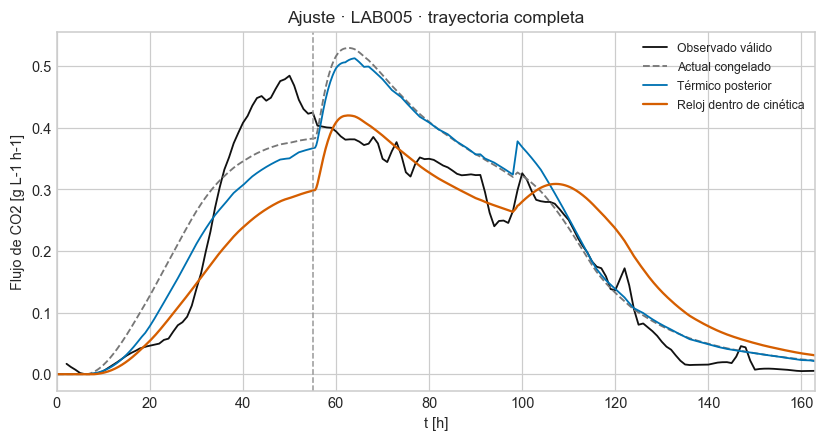

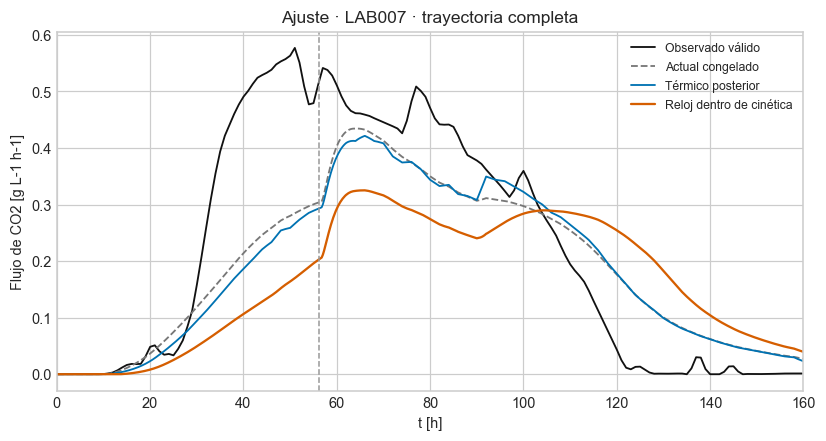

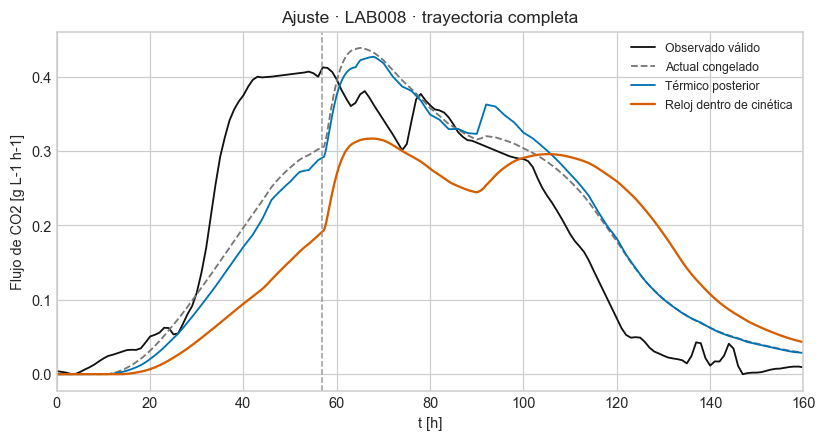

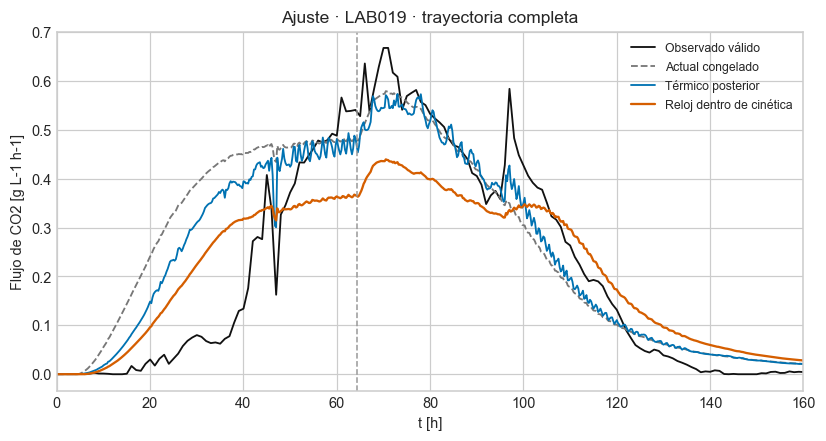

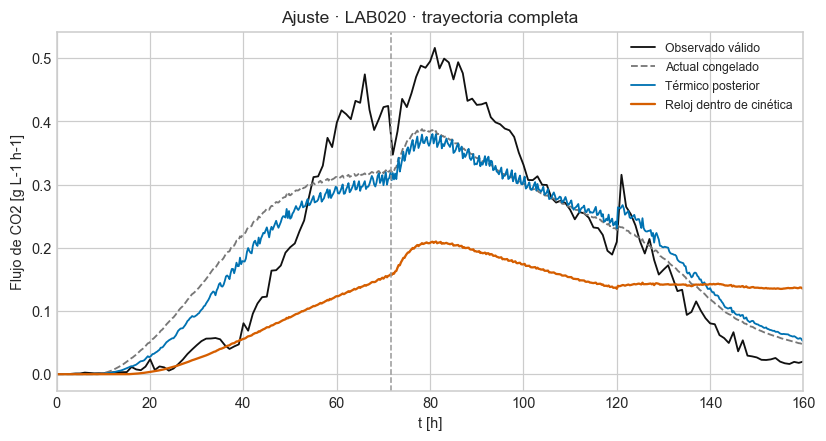

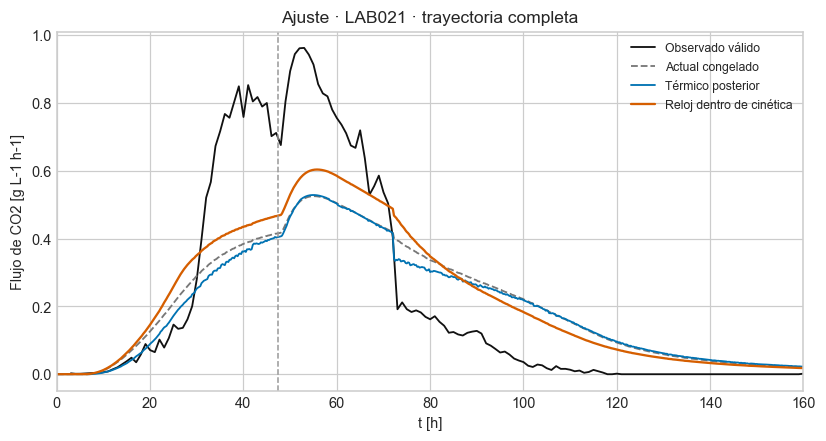

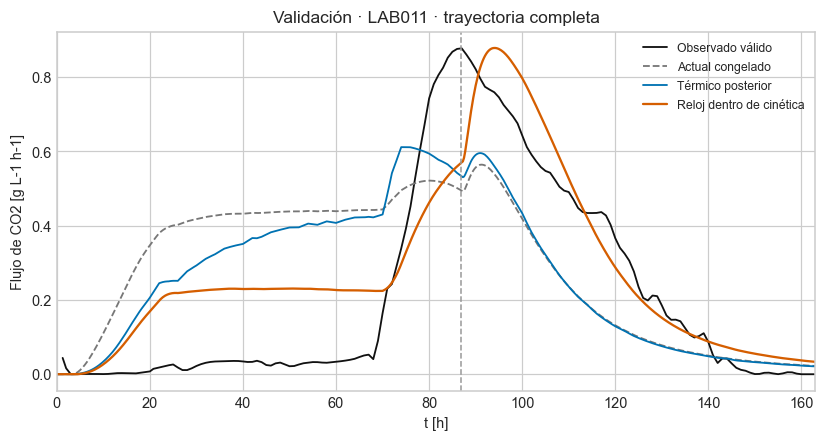

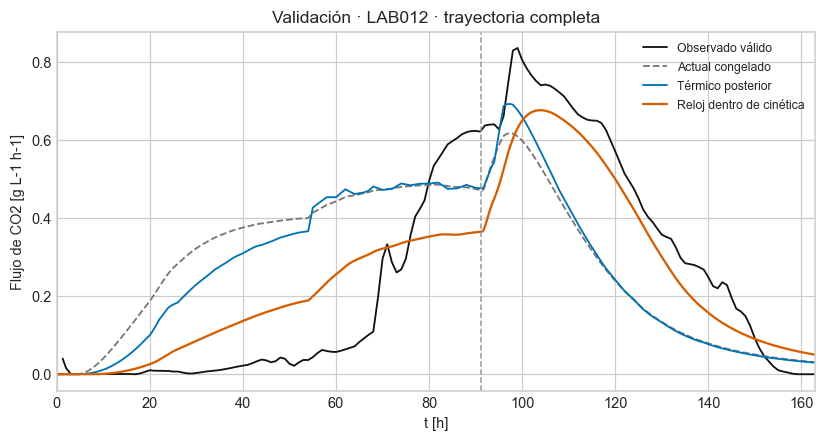

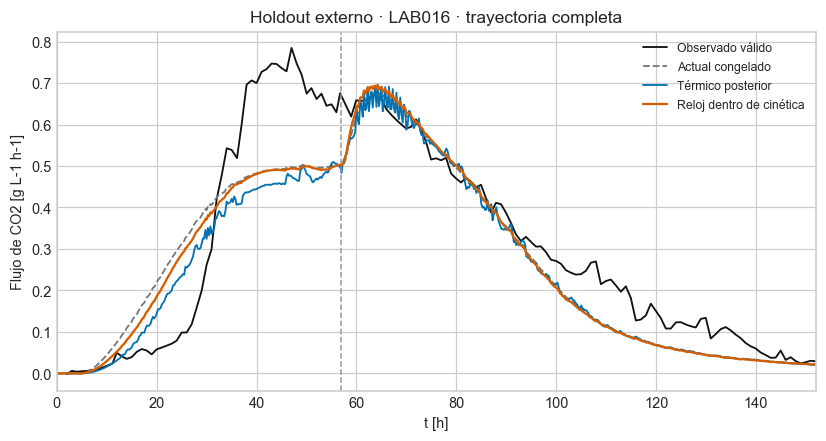

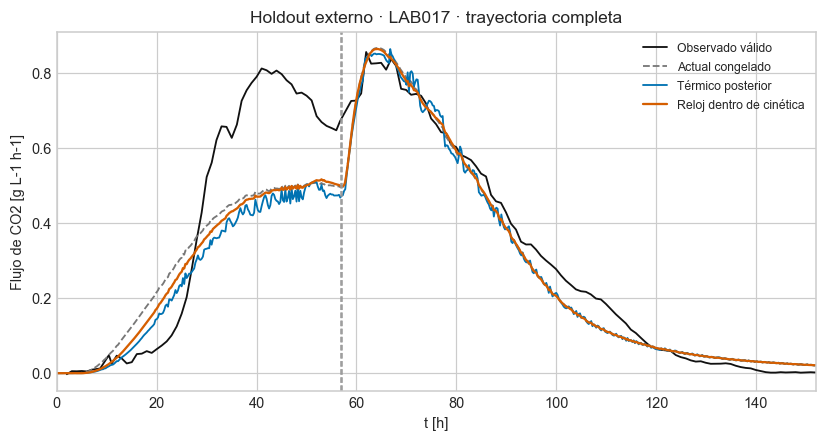

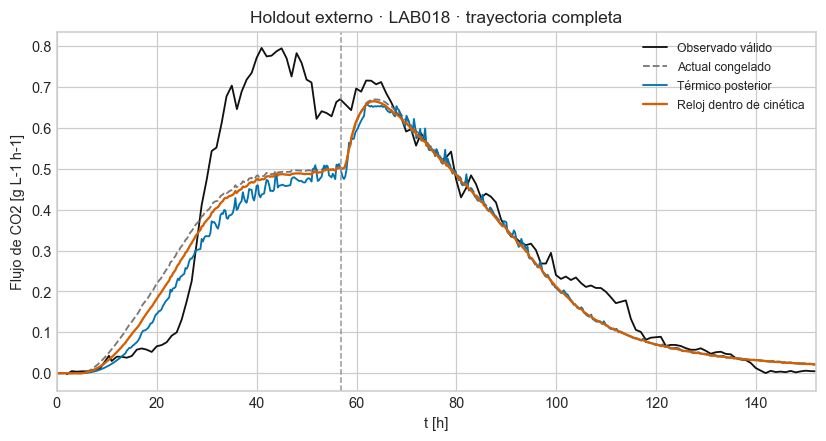

In [26]:
# KINETIC_CLOCK_SECTION_CELL: figuras matplotlib inline (mismo formato que el resto del notebook)
def kinetic_line_chart(series, title, xlabel, ylabel, vlines=(), width=7.6, height=4.1,
                       xlim=None, ylim=None):
    """Dibuja las series con el estilo global del notebook y las muestra inline."""
    fig, ax = plt.subplots(figsize=(width, height))
    for item in series:
        ax.plot(
            np.asarray(item['x'], float),
            np.asarray(item['y'], float),
            color=item['color'],
            linestyle='--' if item.get('dash') else '-',
            linewidth=0.6 * float(item.get('width', 2)),
            label=item['label'],
        )
    for value in vlines:
        ax.axvline(float(value), color='#999999', linestyle='--', linewidth=1.0)
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(loc='best', fontsize=8, framealpha=0.9)
    fig.tight_layout()
    plt.show()


comparison_groups = (
    ('Ajuste', TRAIN_LABS), ('Validación', VALIDATION_LABS), ('Holdout externo', EXTERNAL_LABS),
)
for group_title, labs in comparison_groups:
    for lab in labs:
        observed = transient_full_support[lab]
        current = all_curves[('actual', lab)]
        postprocessed = all_curves[(SELECTED_MODEL, lab)]
        kinetic = kinetic_curves[(SELECTED_KINETIC_MODEL, lab)]
        kinetic_line_chart(
            [
                {'x': observed['t_h'], 'y': observed['co2_rate_g_l_h'], 'label': 'Observado válido', 'color': '#111111', 'width': 2.0},
                {'x': current['t_h'], 'y': current['predicted'], 'label': 'Actual congelado', 'color': '#777777', 'dash': '6,4'},
                {'x': postprocessed['t_h'], 'y': postprocessed['predicted'], 'label': 'Térmico posterior', 'color': '#0072B2'},
                {'x': kinetic['t_h'], 'y': kinetic['predicted'], 'label': 'Reloj dentro de cinética', 'color': '#D55E00', 'width': 2.5},
            ],
            f'{group_title} · {lab} · trayectoria completa', 't [h]',
            'Flujo de CO2 [g L-1 h-1]',
            vlines=[event for event, _ in transient_schedules[lab]],
            xlim=(0.0, float(kinetic['t_h'].max())),
        )


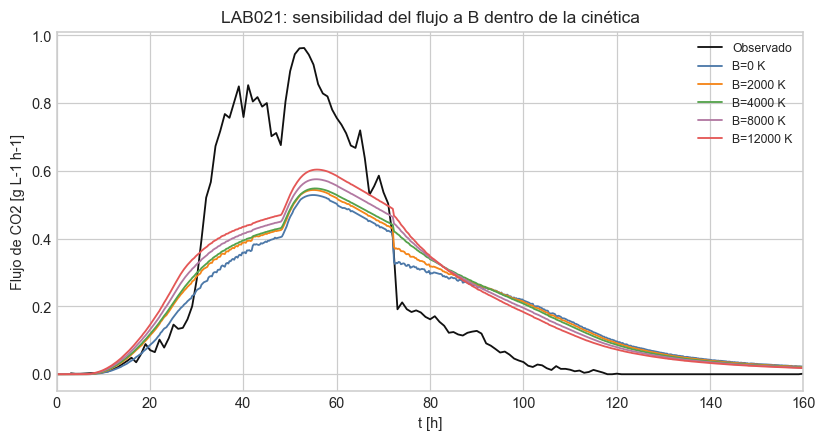

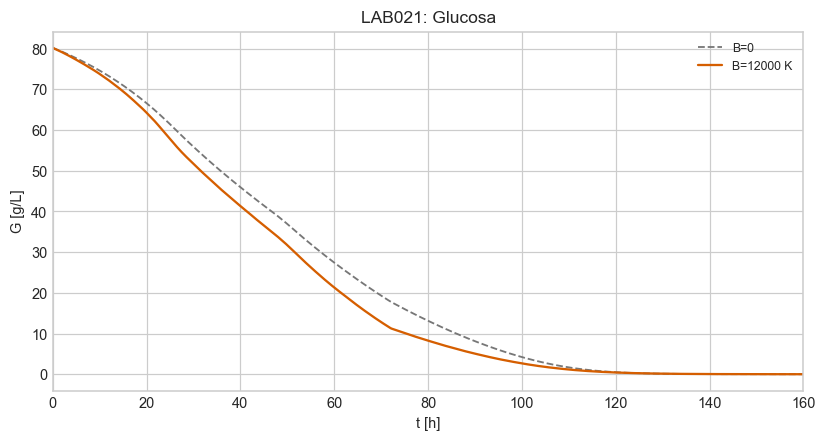

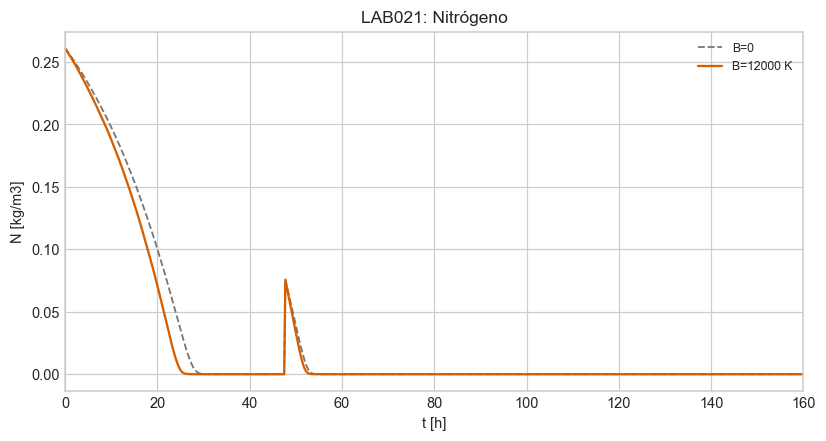

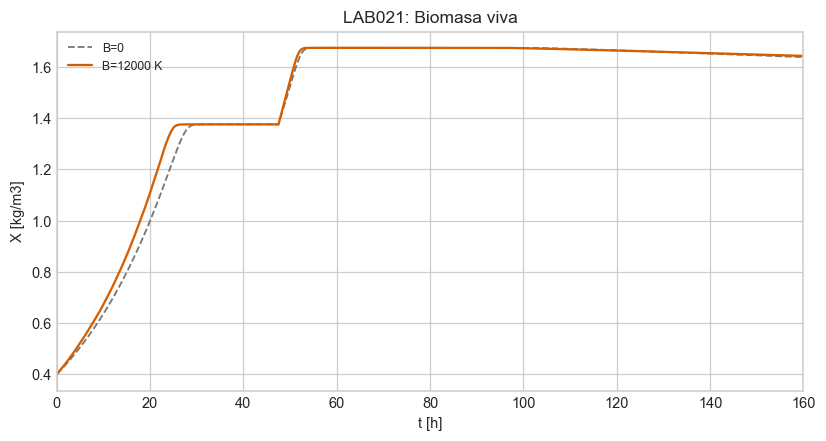

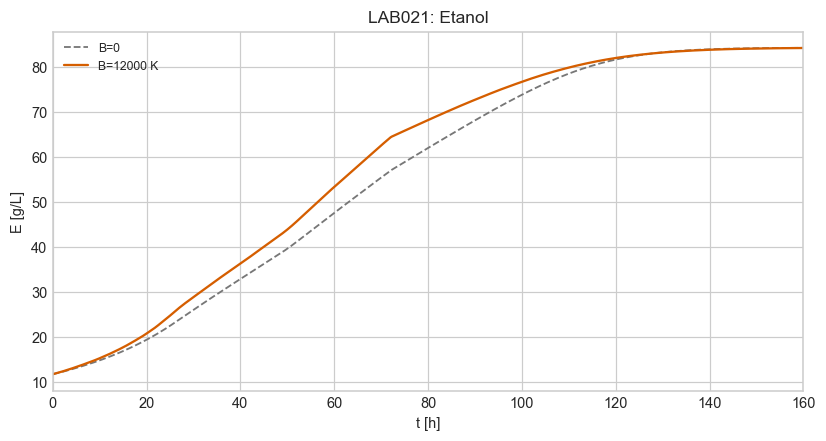

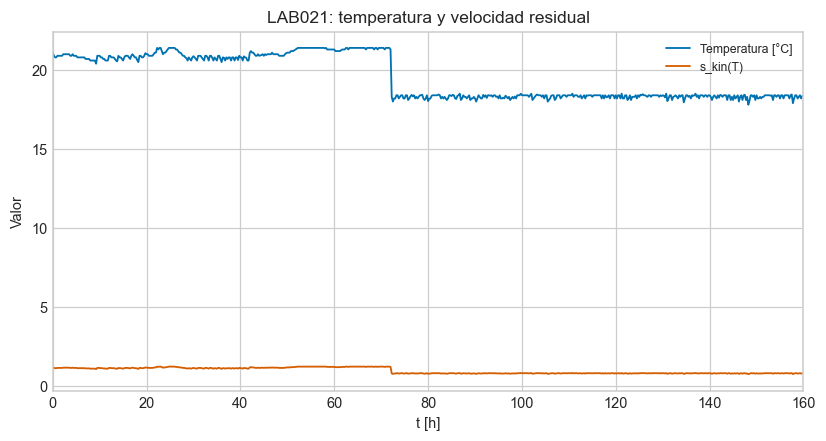

In [27]:
# KINETIC_CLOCK_SECTION_CELL: efecto de B y estados internos de LAB021
lab = 'LAB021'
observed = transient_full_support[lab]
selected_B = selected_kinetic_result['B_kin_extra_K']
base_profile = kinetic_profiles[(0.0, lab)]
selected_profile = kinetic_profiles[(selected_B, lab)]

series = [{'x': observed['t_h'], 'y': observed['co2_rate_g_l_h'], 'label': 'Observado', 'color': '#111111', 'width': 2.0}]
palette = ('#4C78A8', '#F58518', '#54A24B', '#B279A2', '#E45756')
for color, B_kin in zip(palette, KINETIC_CLOCK_CONFIG['B_grid_K']):
    candidate = kinetic_candidate_name('cin_global_full', B_kin)
    curve = kinetic_curves[(candidate, lab)]
    series.append({'x': curve['t_h'], 'y': curve['predicted'], 'label': f'B={B_kin:g} K', 'color': color})
kinetic_line_chart(series, 'LAB021: sensibilidad del flujo a B dentro de la cinética',
                   't [h]', 'Flujo de CO2 [g L-1 h-1]',
                   xlim=(0.0, float(selected_profile['t_h'].max())))

for state, title, ylabel in (
    ('G', 'Glucosa', 'G [g/L]'), ('N', 'Nitrógeno', 'N [kg/m3]'),
    ('X', 'Biomasa viva', 'X [kg/m3]'), ('E', 'Etanol', 'E [g/L]'),
):
    kinetic_line_chart(
        [
            {'x': base_profile['t_h'], 'y': base_profile['core_with'][state], 'label': 'B=0', 'color': '#777777', 'dash': '6,4'},
            {'x': selected_profile['t_h'], 'y': selected_profile['core_with'][state], 'label': f'B={selected_B:g} K', 'color': '#D55E00', 'width': 2.5},
        ],
        f'LAB021: {title}', 't [h]', ylabel,
        xlim=(0.0, float(selected_profile['t_h'].max())),
    )

kinetic_line_chart(
    [
        {'x': selected_profile['t_h'], 'y': selected_profile['temperature_C'], 'label': 'Temperatura [°C]', 'color': '#0072B2'},
        {'x': selected_profile['t_h'], 'y': selected_profile['speed'], 'label': 's_kin(T)', 'color': '#D55E00'},
    ],
    'LAB021: temperatura y velocidad residual', 't [h]', 'Valor',
    xlim=(0.0, float(selected_profile['t_h'].max())),
)


## Control manual del reloj dentro de la cinética

Edita el diccionario siguiente y ejecuta sus dos celdas. Esta prueba manual no cambia el ajuste ni el ranking formal.

In [28]:
# KINETIC_CLOCK_SECTION_CELL: parámetros manuales independientes
KINETIC_MANUAL = {
    'lab': 'LAB021',
    'B_kin_extra_K': 8000.0,
    'tau_adapt_ref_h': 18.0,
    'B_release_K': 4000.0,
    'adaptation': True,
    'release_T': True,
}


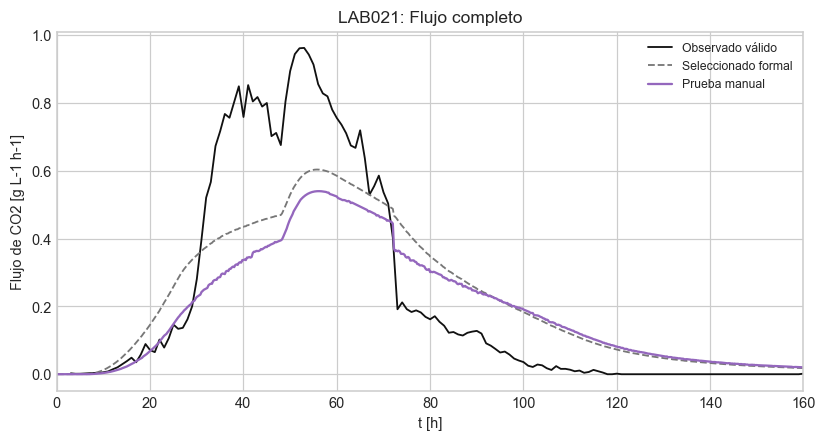

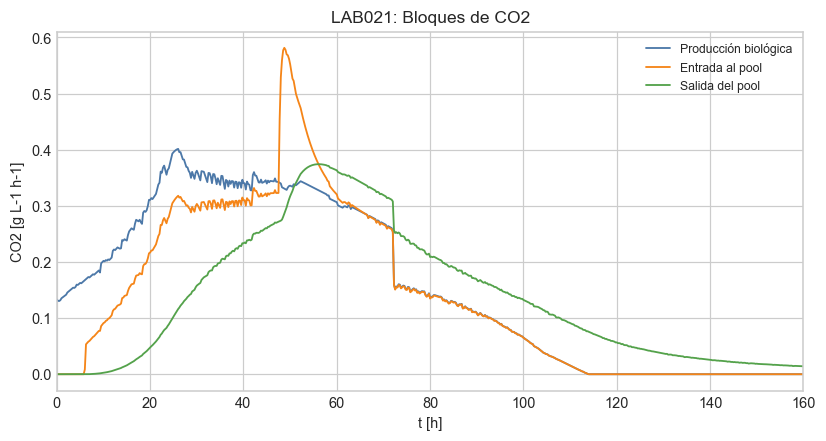

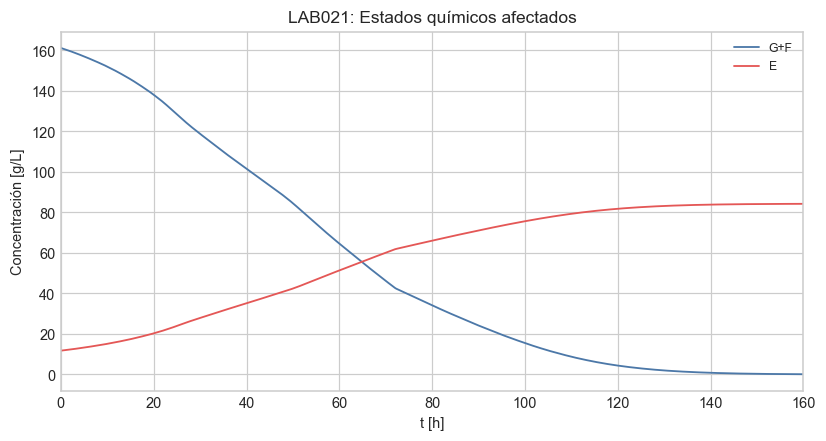

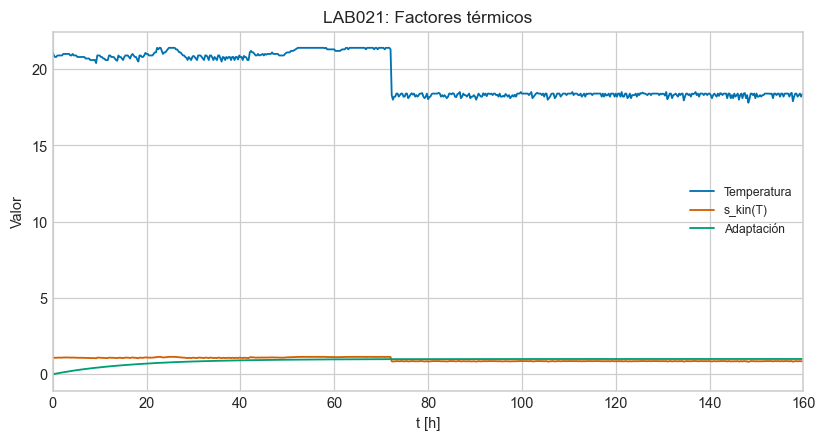

Prueba manual independiente: ajuste y ranking intactos.


In [29]:
# KINETIC_CLOCK_SECTION_CELL: explorador manual; recalcula sólo el laboratorio elegido
_formal_kinetic_signature = (kinetic_validation_ranking.to_json(), json.dumps(kinetic_fit_results, sort_keys=True))
manual_lab = str(KINETIC_MANUAL['lab'])
assert manual_lab in KINETIC_TEST_LABS
manual_B = float(KINETIC_MANUAL['B_kin_extra_K'])
manual_profile = kinetic_profiles.get((manual_B, manual_lab))
if manual_profile is None:
    manual_profile = build_kinetic_clock_profile(manual_lab, manual_B)
manual_spec = {'adaptation': bool(KINETIC_MANUAL['adaptation']), 'release_T': bool(KINETIC_MANUAL['release_T'])}
manual_curve = curve_from_kinetic_profile(manual_profile, manual_spec, KINETIC_MANUAL)
formal_curve = kinetic_curves[(SELECTED_KINETIC_MODEL, manual_lab)]
observed = transient_full_support[manual_lab]

manual_charts = (
    ([
        {'x': observed['t_h'], 'y': observed['co2_rate_g_l_h'], 'label': 'Observado válido', 'color': '#111111'},
        {'x': formal_curve['t_h'], 'y': formal_curve['predicted'], 'label': 'Seleccionado formal', 'color': '#777777', 'dash': '6,4'},
        {'x': manual_curve['t_h'], 'y': manual_curve['predicted'], 'label': 'Prueba manual', 'color': '#9467BD', 'width': 2.5},
    ], 'Flujo completo', 'Flujo de CO2 [g L-1 h-1]'),
    ([
        {'x': manual_curve['t_h'], 'y': manual_curve['qbio'], 'label': 'Producción biológica', 'color': '#4C78A8'},
        {'x': manual_curve['t_h'], 'y': manual_curve['q_input'], 'label': 'Entrada al pool', 'color': '#F58518'},
        {'x': manual_curve['t_h'], 'y': manual_curve['q_output'], 'label': 'Salida del pool', 'color': '#54A24B'},
    ], 'Bloques de CO2', 'CO2 [g L-1 h-1]'),
    ([
        {'x': manual_profile['t_h'], 'y': manual_profile['core_with']['G']+manual_profile['core_with']['F'], 'label': 'G+F', 'color': '#4C78A8'},
        {'x': manual_profile['t_h'], 'y': manual_profile['core_with']['E'], 'label': 'E', 'color': '#E45756'},
    ], 'Estados químicos afectados', 'Concentración [g/L]'),
    ([
        {'x': manual_profile['t_h'], 'y': manual_profile['temperature_C'], 'label': 'Temperatura', 'color': '#0072B2'},
        {'x': manual_profile['t_h'], 'y': manual_profile['speed'], 'label': 's_kin(T)', 'color': '#D55E00'},
        {'x': manual_curve['t_h'], 'y': manual_curve['adaptation'], 'label': 'Adaptación', 'color': '#009E73'},
    ], 'Factores térmicos', 'Valor'),
)
for series, title, ylabel in manual_charts:
    kinetic_line_chart(series, f'{manual_lab}: {title}', 't [h]', ylabel,
                       xlim=(0.0, float(manual_curve['t_h'].max())))
assert _formal_kinetic_signature == (kinetic_validation_ranking.to_json(), json.dumps(kinetic_fit_results, sort_keys=True))
print('Prueba manual independiente: ajuste y ranking intactos.')


## Explorador manual

Después de ejecutar todo una vez, edita `MANUAL`, ejecuta su celda y luego esta celda. No recalibra ni cambia el ranking formal.


In [30]:
print('Para esta hipótesis se usa el explorador cinético de la sección anterior.')

Para esta hipótesis se usa el explorador cinético de la sección anterior.


In [31]:
protected_after = {str(path): sha256(path) for path in PROTECTED_PATHS}
assert protected_after == protected_before
assert theta_full == frozen_theta_snapshot
assert co2_params == frozen_co2_snapshot
assert set(TRAIN_LABS).isdisjoint(VALIDATION_LABS + EXTERNAL_LABS)
assert set(VALIDATION_LABS).isdisjoint(EXTERNAL_LABS)
assert all(np.isfinite(curve['predicted']).all() and (curve['predicted'] >= 0).all() for curve in all_curves.values())
assert all(np.isfinite(curve['dissolved_g_l']).all() and (curve['dissolved_g_l'] >= 0).all() for curve in all_curves.values())
assert all(np.diff(curve['thermal_clock_h']).min() >= 0 for curve in all_curves.values())

validation_current = float(validation_ranking.loc[validation_ranking['model'].eq('actual'), 'median_NRMSE'].iloc[0])
validation_selected = float(validation_ranking.loc[validation_ranking['model'].eq(SELECTED_MODEL), 'median_NRMSE'].iloc[0])
external_summary = metric_table[metric_table['role'].eq('external_holdout')].groupby('model')['NRMSE_peak'].median()
external_current = float(external_summary['actual'])
external_selected = float(external_summary[SELECTED_MODEL])
selected_B_clock = float(selected_params.get('B_clock_extra_K', 0.0))
selected_tau_adapt = float(selected_params.get('tau_adapt_ref_h', np.nan))
selected_B_release = float(selected_params.get('B_release_K', 0.0))
display(Markdown(
    f'**Estructura seleccionada por LAB011–LAB012: `{SELECTED_MODEL}`.**  '
    f'NRMSE mediano de validación: {validation_current:.4f} → {validation_selected:.4f}; '
    f'holdout LAB016–LAB018: {external_current:.4f} → {external_selected:.4f}.  '
    f'Parámetros seleccionados: $B_{{clock,extra}}={selected_B_clock:.3f}$ K, '
    f'$\\tau_{{adapt}}={selected_tau_adapt:.3f}$ h y $B_{{release}}={selected_B_release:.1f}$ K '
    f'($E_{{release}}\\approx {8.314e-3 * selected_B_release:.1f}$ kJ/mol).  '
    'El reloj adicional cae prácticamente a cero: con esta formulación y estos datos no se identifica una '
    'compresión global residual por encima de la temperatura ya incluida en la cinética. La adaptación y $k(T)$ '
    'mejoran LAB011–LAB012, pero no transfieren esa mejora al holdout externo. En los cambios de setpoint, $k(T)$ '
    'corrige la dirección de LAB020 y acerca LAB019/LAB021, aunque la respuesta sigue siendo demasiado débil.  '
    'La selección prueba capacidad predictiva del flujo; no demuestra que adaptación o liberación térmica sean '
    'mecanismos únicos. Pool, `theta_full`, nutrición y LAB016–LAB018 permanecieron fuera del ajuste.'
))
print('VALIDACIÓN COMPLETA: sin escrituras en results y artefactos previos intactos.')


# KINETIC_CLOCK_SECTION_CELL: validación de la prueba dentro de la cinética
assert set(KINETIC_TEST_LABS) == set(TRAIN_LABS + VALIDATION_LABS + EXTERNAL_LABS)
assert set(EXTERNAL_LABS).isdisjoint(TRAIN_LABS + VALIDATION_LABS)
assert all(np.isfinite(curve['predicted']).all() and (curve['predicted'] >= 0).all()
           for curve in kinetic_curves.values())
assert all(np.isfinite(profile['core_with'].to_numpy(float)).all()
           for profile in kinetic_profiles.values())
kinetic_validation_selected = float(kinetic_validation_ranking.iloc[0]['median_NRMSE'])
kinetic_external_summary = kinetic_metric_table[
    kinetic_metric_table['role'].eq('external_holdout') & kinetic_metric_table['model'].eq(SELECTED_KINETIC_MODEL)
]['NRMSE_peak'].median()
display(Markdown(
    f'**Prueba con reloj dentro de toda la cinética:** `{SELECTED_KINETIC_MODEL}`; '
    f'$B_{{kin,extra}}={selected_kinetic_result["B_kin_extra_K"]:.0f}$ K. '
    f'NRMSE mediano en LAB011–LAB012: {kinetic_validation_selected:.4f}; '
    f'holdout LAB016–LAB018: {kinetic_external_summary:.4f}. '
    'Esta formulación cambia simultáneamente biomasa, nutrientes, azúcares, etanol, glicerol y producción de CO2. '
    f'El valor seleccionado coincide con el extremo superior de la grilla ({max(KINETIC_CLOCK_CONFIG["B_grid_K"]):.0f} K), '
    'por lo que no representa un óptimo identificado: la validación todavía favorece mayor sensibilidad térmica. '
    f'El error mediano absoluto de onset en validación sigue siendo '
    f'{float(kinetic_validation_ranking.iloc[0]["median_abs_onset_h"]):.1f} h, así que la activación temprana no queda resuelta. '
    'Los pulsos permanecen como saltos en tiempo real; theta_full, el pool base y el transitorio nutricional no se recalibraron.'
))


**Estructura seleccionada por LAB011–LAB012: `termico_completo`.**  NRMSE mediano de validación: 0.2968 → 0.2639; holdout LAB016–LAB018: 0.1387 → 0.1446.  Parámetros seleccionados: $B_{clock,extra}=0.002$ K, $\tau_{adapt}=9.379$ h y $B_{release}=4306.8$ K ($E_{release}\approx 35.8$ kJ/mol).  El reloj adicional cae prácticamente a cero: con esta formulación y estos datos no se identifica una compresión global residual por encima de la temperatura ya incluida en la cinética. La adaptación y $k(T)$ mejoran LAB011–LAB012, pero no transfieren esa mejora al holdout externo. En los cambios de setpoint, $k(T)$ corrige la dirección de LAB020 y acerca LAB019/LAB021, aunque la respuesta sigue siendo demasiado débil.  La selección prueba capacidad predictiva del flujo; no demuestra que adaptación o liberación térmica sean mecanismos únicos. Pool, `theta_full`, nutrición y LAB016–LAB018 permanecieron fuera del ajuste.

VALIDACIÓN COMPLETA: sin escrituras en results y artefactos previos intactos.


**Prueba con reloj dentro de toda la cinética:** `cin_global_adapt__Bkin_12000`; $B_{kin,extra}=12000$ K. NRMSE mediano en LAB011–LAB012: 0.1517; holdout LAB016–LAB018: 0.1352. Esta formulación cambia simultáneamente biomasa, nutrientes, azúcares, etanol, glicerol y producción de CO2. El valor seleccionado coincide con el extremo superior de la grilla (12000 K), por lo que no representa un óptimo identificado: la validación todavía favorece mayor sensibilidad térmica. El error mediano absoluto de onset en validación sigue siendo 45.0 h, así que la activación temprana no queda resuelta. Los pulsos permanecen como saltos en tiempo real; theta_full, el pool base y el transitorio nutricional no se recalibraron.